# 🏦 Bank Müştərilərinin Kredit Ödəmə Qabiliyyətinə Görə Klasterləşdirilməsi

**Rol:** Bank Riski və Kredit Analitikası üzrə Baş Məlumat Elmi Mütəxəssisi (*Senior Data Scientist*)  
**Metodologiya:** Nəzarətsiz Maşın Öyrənməsi (*Unsupervised Machine Learning*) — PCA, TruncatedSVD, K-Means və İerarxik (Ward) Klasterləşdirmə  

---

## 📋 Layihənin Biznes Məqsədi və Strukturu
Müasir bankçılıqda kredit portfelinin sağlamlığını qorumaq, defolt (kreditin qaytarılmaması) riskini minimuma endirmək və hər müştəri seqmentinə fərdiləşdirilmiş kredit siyasəti tətbiq etmək üçün müştərilərin maliyyə davranışlarına görə seqmentləşdirilməsi həyati əhəmiyyət daşıyır. 

Bu analitik hesabatda **1,600 bank müştərisinin** gəlir, borc yükü, gecikmə tarixçəsi və FICO kredit reytinqi göstəriciləri əsasında **6 mərhələli** tam elmi-praktiki boru xətti (*pipeline*) qurulmuşdur:

1. **Mərhələ 1 — Məlumatın Simulyasiyası və İlkin Emalı (*Data Simulation & Preprocessing*):** Bank domeni üzrə realist sintetik datasetin yaradılması, çatışmayan dəyərlərin (*missing values*) və kənar qiymətlərin (*outliers*) təhlili/təmizlənməsi.
2. **Mərhələ 2 — Xüsusiyyətlərin Miqyaslanması (*Feature Scaling*):** Məsafə əsaslı klaster alqoritmləri üçün `StandardScaler` ilə z-score normallaşdırılması.
3. **Mərhələ 3 — Ölçülərin Azaldılması (*Dimensionality Reduction — PCA & TruncatedSVD*):** Yüksək ölçülü maliyyə fəzasının əsas komponentlərə proyeksiyası, kümülatif dispersiya təhlili və PCA ilə SVD-nin müqayisəsi.
4. **Mərhələ 4 — K-Means Klasterləşdirmə:** *Elbow (WCSS)* və *Silhouette Score* metodları ilə optimal seqment sayının ($k$) seçilməsi və 2D PCA fəzasında centroid-lərlə vizuallaşdırma.
5. **Mərhələ 5 — İerarxik (Aqqlomerativ) Klasterləşdirmə:** *Ward Linkage* metodu ilə Dendroqramın qurulması, optimal kəsim həddinin (*threshold*) təyini və K-Means nəticələri ilə çarpaz müqayisə.
6. **Mərhələ 6 — Bank Riski və Biznes Klaster Profilləri (*Cluster Profiling & Credit Policy*):** Hər klasterin maliyyə portretinin çıxarılması, risk statusunun verilməsi və Bank İdarə Heyəti üçün konkret kredit siyasəti tövsiyələri.

---
## 1. Mərhələ: Məlumatın Hazırlanması (Data Simulation & Preprocessing)

### 1.1. Kitabxanaların Yüklənməsi və Qlobal Tənzimləmələr
Analizdə məlumatların emalı üçün `numpy` və `pandas`, statistik hesablamalar və ierarxik klasterləşdirmə üçün `scipy`, maşın öyrənməsi modelləri üçün `scikit-learn`, eləcə də yüksək keyfiyyətli vizuallaşdırma üçün `matplotlib` və `seaborn` kitabxanalarından istifadə edirik.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings("ignore")
np.random.seed(42)

# Qrafiklərin vizual standartları
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Kitabxanalar uğurla yükləndi və qlobal parametrlər tənzimləndi.")

Kitabxanalar uğurla yükləndi və qlobal parametrlər tənzimləndi.


### 1.2. Bank Domeni Üzrə Realist Sintetik Məlumatın Yaradılması
Real bank portfelini təmsil etmək üçün **1,600 müştəridən** ibarət sintetik dataset yaradırıq. Domen reallığını qorumaq üçün müştərilər 4 gizli (*latent*) maliyyə davranış qrupundan generasiya olunur:
- **Seqment A (VIP / Yüksək Gəlirli Etibarlı Müştərilər):** Yüksək gəlir, aşağı borc-gəlir nisbəti (DTI), 0 gecikmə günü, yüksək FICO skoru (740–850).
- **Seqment B (Sabit Orta Təbəqə / Standart Müştərilər):** Orta-yüksək sabit gəlir, idarəolunan cari borc, nadir gecikmələr (0–5 gün), yaxşı FICO skoru (660–750).
- **Seqment C (Borc Yüklü / Gərginlik Həddində Olan Müştərilər):** Orta gəlirə qarşı yüksək cari borc və çoxsaylı kredit xətləri, yüksək DTI, orta-aşağı FICO skoru (560–660).
- **Seqment D (Yüksək Riskli / Gecikməyə Meyilli "Subprime" Müştərilər):** Aşağı gəlir, yüksək borc yükü, ciddi gecikmə günləri (30–120+ gün) və aşağı FICO skoru (300–560).

Bundan əlavə, real bank bazalarında rast gəlinən **çatışmayan dəyərlər (~1.5% missing values)** və **ekstremal kənar qiymətlər (~1% outliers)** də məqsədli şəkildə datasetə daxil edilir ki, təmizləmə mərhələsini tam tətbiq edək.

In [2]:
def generate_bank_credit_dataset(n_samples: int = 1600, random_state: int = 42) -> pd.DataFrame:
    """Bank müştərilərinin kredit ödəmə qabiliyyətini əks etdirən sintetik dataset yaradır."""
    rng = np.random.default_rng(random_state)
    
    # 4 latent seqment üzrə bərabər müştəri paylanması (hər seqmentdə 400 müştəri)
    n_vip = n_samples // 4
    n_std = n_samples // 4
    n_lev = n_samples // 4
    n_sub = n_samples - (n_vip + n_std + n_lev)

    # 1. Aylıq Gəlir (AZN)
    gelir = np.concatenate([
        rng.normal(7200, 480, n_vip),
        rng.normal(3200, 320, n_std),
        rng.normal(2400, 260, n_lev),
        rng.normal(1050, 180, n_sub),
    ]).clip(450, 15000)

    # 2. Cari Borc (AZN)
    cari_borc = np.concatenate([
        rng.normal(2500, 700, n_vip),
        rng.normal(9500, 1200, n_std),
        rng.normal(26000, 2200, n_lev),
        rng.normal(14500, 1600, n_sub),
    ]).clip(200, 60000)

    # 3. Aylıq Xərc (AZN)
    ayliq_xerc = np.concatenate([
        rng.normal(3100, 280, n_vip),
        rng.normal(1500, 180, n_std),
        rng.normal(1850, 200, n_lev),
        rng.normal(820, 120, n_sub),
    ]).clip(300, 12000)

    # 4. Borc / Gəlir Nisbəti (DTI)
    dti = np.concatenate([
        rng.normal(0.12, 0.025, n_vip),
        rng.normal(0.38, 0.035, n_std),
        rng.normal(0.68, 0.045, n_lev),
        rng.normal(0.95, 0.055, n_sub),
    ]).clip(0.05, 1.45)

    # 5. Gecikmə Gün Sayı (DPD - Days Past Due)
    gecikme_gun = np.concatenate([
        rng.poisson(0.2, n_vip),
        rng.normal(5, 1.5, n_std),
        rng.normal(22, 3.5, n_lev),
        rng.normal(85, 9.0, n_sub),
    ]).clip(0, 180).round()

    # 6. Kredit Xətti Sayı (aktiv kredit və kredit kartlarının sayı)
    kredit_xetti = np.concatenate([
        rng.integers(1, 3, n_vip),
        rng.integers(3, 5, n_std),
        rng.integers(8, 11, n_lev),
        rng.integers(5, 7, n_sub),
    ]).astype(float)

    # 7. Kredit Skoru FICO (300 - 850 diapazonu)
    fico = np.concatenate([
        rng.normal(810, 15, n_vip),
        rng.normal(690, 18, n_std),
        rng.normal(585, 20, n_lev),
        rng.normal(430, 25, n_sub),
    ]).clip(300, 850).round()

    df_syn = pd.DataFrame({
        "Musteri_ID": [f"CUST_{i:04d}" for i in range(1, n_samples + 1)],
        "Ayliq_Gelir": np.round(gelir, 2),
        "Cari_Borc": np.round(cari_borc, 2),
        "Borc_Gelir_Nisbeti": np.round(dti, 4),
        "Gecikme_Gun_Sayi": gecikme_gun,
        "Kredit_Xetti_Sayi": kredit_xetti,
        "Kredit_Skoru_FICO": fico,
        "Ayliq_Xerc": np.round(ayliq_xerc, 2),
    })

    # Sətirləri təsadüfi qarışdıraq
    df_syn = df_syn.sample(frac=1.0, random_state=random_state).reset_index(drop=True)
    df_syn["Musteri_ID"] = [f"CUST_{i:04d}" for i in range(1, n_samples + 1)]

    # Realist kənar qiymətlər (Outliers - 12 sətirdə anomal sıçrayışlar)
    outlier_idx = rng.choice(df_syn.index, size=12, replace=False)
    df_syn.loc[outlier_idx[:4], "Ayliq_Gelir"] = [24500.0, 28000.0, 22100.0, 26400.0]
    df_syn.loc[outlier_idx[4:8], "Cari_Borc"] = [78000.0, 85000.0, 92000.0, 81500.0]
    df_syn.loc[outlier_idx[8:], "Gecikme_Gun_Sayi"] = [210.0, 240.0, 195.0, 225.0]

    # Realist çatışmayan dəyərlər (Missing Values - ~1.5%)
    for col in ["Ayliq_Gelir", "Cari_Borc", "Kredit_Skoru_FICO", "Ayliq_Xerc"]:
        miss_idx = rng.choice(df_syn.index, size=18, replace=False)
        df_syn.loc[miss_idx, col] = np.nan

    return df_syn


df_raw = generate_bank_credit_dataset(n_samples=1600, random_state=42)
print(f"Dataset uğurla yaradıldı! Ölçü: {df_raw.shape[0]} sətir, {df_raw.shape[1]} sütun.")
df_raw.head(10)

Dataset uğurla yaradıldı! Ölçü: 1600 sətir, 8 sütun.


,Musteri_ID,Ayliq_Gelir,Cari_Borc,Borc_Gelir_Nisbeti,Gecikme_Gun_Sayi,Kredit_Xetti_Sayi,Kredit_Skoru_FICO,Ayliq_Xerc
0,CUST_0001,"3,665.61","12,147.83",0.45,5.00,3.00,706.00,"1,541.12"
1,CUST_0002,"7,712.87","2,650.71",0.14,0.00,2.00,761.00,"3,359.52"
2,CUST_0003,"7,124.81","1,857.57",0.11,0.00,1.00,842.00,"3,184.87"
3,CUST_0004,"6,712.52","3,140.24",0.10,0.00,2.00,794.00,"3,021.22"
4,CUST_0005,NaN,"22,431.76",0.71,19.00,9.00,600.00,"1,890.33"
5,CUST_0006,NaN,"13,863.56",0.90,89.00,6.00,432.00,797.44
6,CUST_0007,"1,104.35","14,889.44",1.06,72.00,6.00,396.00,868.74
7,CUST_0008,"7,121.92","2,318.91",0.10,0.00,1.00,813.00,"3,128.05"
8,CUST_0009,"3,202.03","6,912.79",0.36,5.00,4.00,693.00,"1,376.35"
9,CUST_0010,"3,791.30","8,256.10",0.37,5.00,4.00,690.00,"1,606.40"


### 1.3. İlkin Statistik Təhlil, Çatışmayan Dəyərlər (Missing Values) və Kənar Qiymətlər (Outliers)
Məlumat bazasının ilkin statistik paylanmasını (`describe()`), çatışmayan dəyərlərin sayını və IQR (*Interquartile Range*) qaydası ilə kənar qiymətləri yoxlayırıq.
- **Missing Value strategiyası:** Maliyyə göstəricilərində (xüsusilə gəlir və borc sütunlarında) asimmetriya və kənar qiymətlər olduğu üçün çatışmayan dəyərləri orta qiymətlə (*mean*) deyil, kənar qiymətlərə dayanıqlı olan **median** ilə doldururuq. və sonra `Borc_Gelir_Nisbeti` sütununu yeniləyirik.
- **Outlier strategiyası:** K-Means və PCA kvadratik məsafələrə həssas olduğu üçün ekstremal kənar qiymətləri `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]` (Winsorization / Clipping) sərhədlərinə sıxışdırırıq ki, tək-tük anomal müştərilər klaster mərkəzlərini (*centroids*) təhrif etməsin.

In [3]:
# Çatışmayan dəyərlərin yoxlanışı
missing_summary = pd.DataFrame({
    "Missing_Sayi": df_raw.isnull().sum(),
    "Missing_Faizi (%)": (df_raw.isnull().sum() / len(df_raw) * 100).round(2)
})
print("=== Çatışmayan Dəyərlərin (Missing Values) Hesabatı ===")
print(missing_summary[missing_summary["Missing_Sayi"] > 0])
print("\n=== İlkin Statistik Göstəricilər (Təmizlənmədən Əvvəl) ===")
df_raw.describe().T

=== Çatışmayan Dəyərlərin (Missing Values) Hesabatı ===
                   Missing_Sayi  Missing_Faizi (%)
Ayliq_Gelir                  18               1.12
Cari_Borc                    18               1.12
Kredit_Skoru_FICO            18               1.12
Ayliq_Xerc                   18               1.12

=== İlkin Statistik Göstəricilər (Təmizlənmədən Əvvəl) ===


,count,mean,std,min,25%,50%,75%,max
Ayliq_Gelir,"1,582.00","3,509.28","2,561.48",517.99,"1,654.80","2,737.76","6,152.02","28,000.00"
Cari_Borc,"1,582.00","13,329.98","9,477.92",366.66,"4,860.84","11,875.07","21,330.41","92,000.00"
Borc_Gelir_Nisbeti,"1,600.00",0.53,0.32,0.05,0.27,0.49,0.80,1.12
Gecikme_Gun_Sayi,"1,600.00",28.31,35.30,0.00,2.00,10.50,62.25,240.00
Kredit_Xetti_Sayi,"1,600.00",4.87,2.82,1.00,2.75,4.50,6.50,10.00
Kredit_Skoru_FICO,"1,582.00",627.21,141.69,357.00,495.50,641.50,738.75,850.00
Ayliq_Xerc,"1,582.00","1,816.97",856.47,442.76,"1,112.47","1,664.69","2,339.74","3,964.78"


Təmizləmədən sonra qalan Missing Value sayı: 0


,Xususiyyet,Q1 (25%),Q3 (75%),IQR,Ashagi_Hedd,Yuxari_Hedd,Outlier_Sayi
0,Ayliq_Gelir,"1,824.09","4,019.65","2,195.56","-1,469.26","7,312.99",158
1,Cari_Borc,"6,623.17","19,472.60","12,849.43","-12,650.97","38,746.75",4
2,Borc_Gelir_Nisbeti,0.27,0.80,0.53,-0.53,1.60,0
3,Gecikme_Gun_Sayi,2.00,62.25,60.25,-88.38,152.62,4
4,Kredit_Xetti_Sayi,2.75,6.50,3.75,-2.88,12.12,0
5,Kredit_Skoru_FICO,533.00,732.00,199.00,234.50,"1,030.50",0
6,Ayliq_Xerc,"1,147.16","2,291.77","1,144.61",-569.75,"4,008.68",0


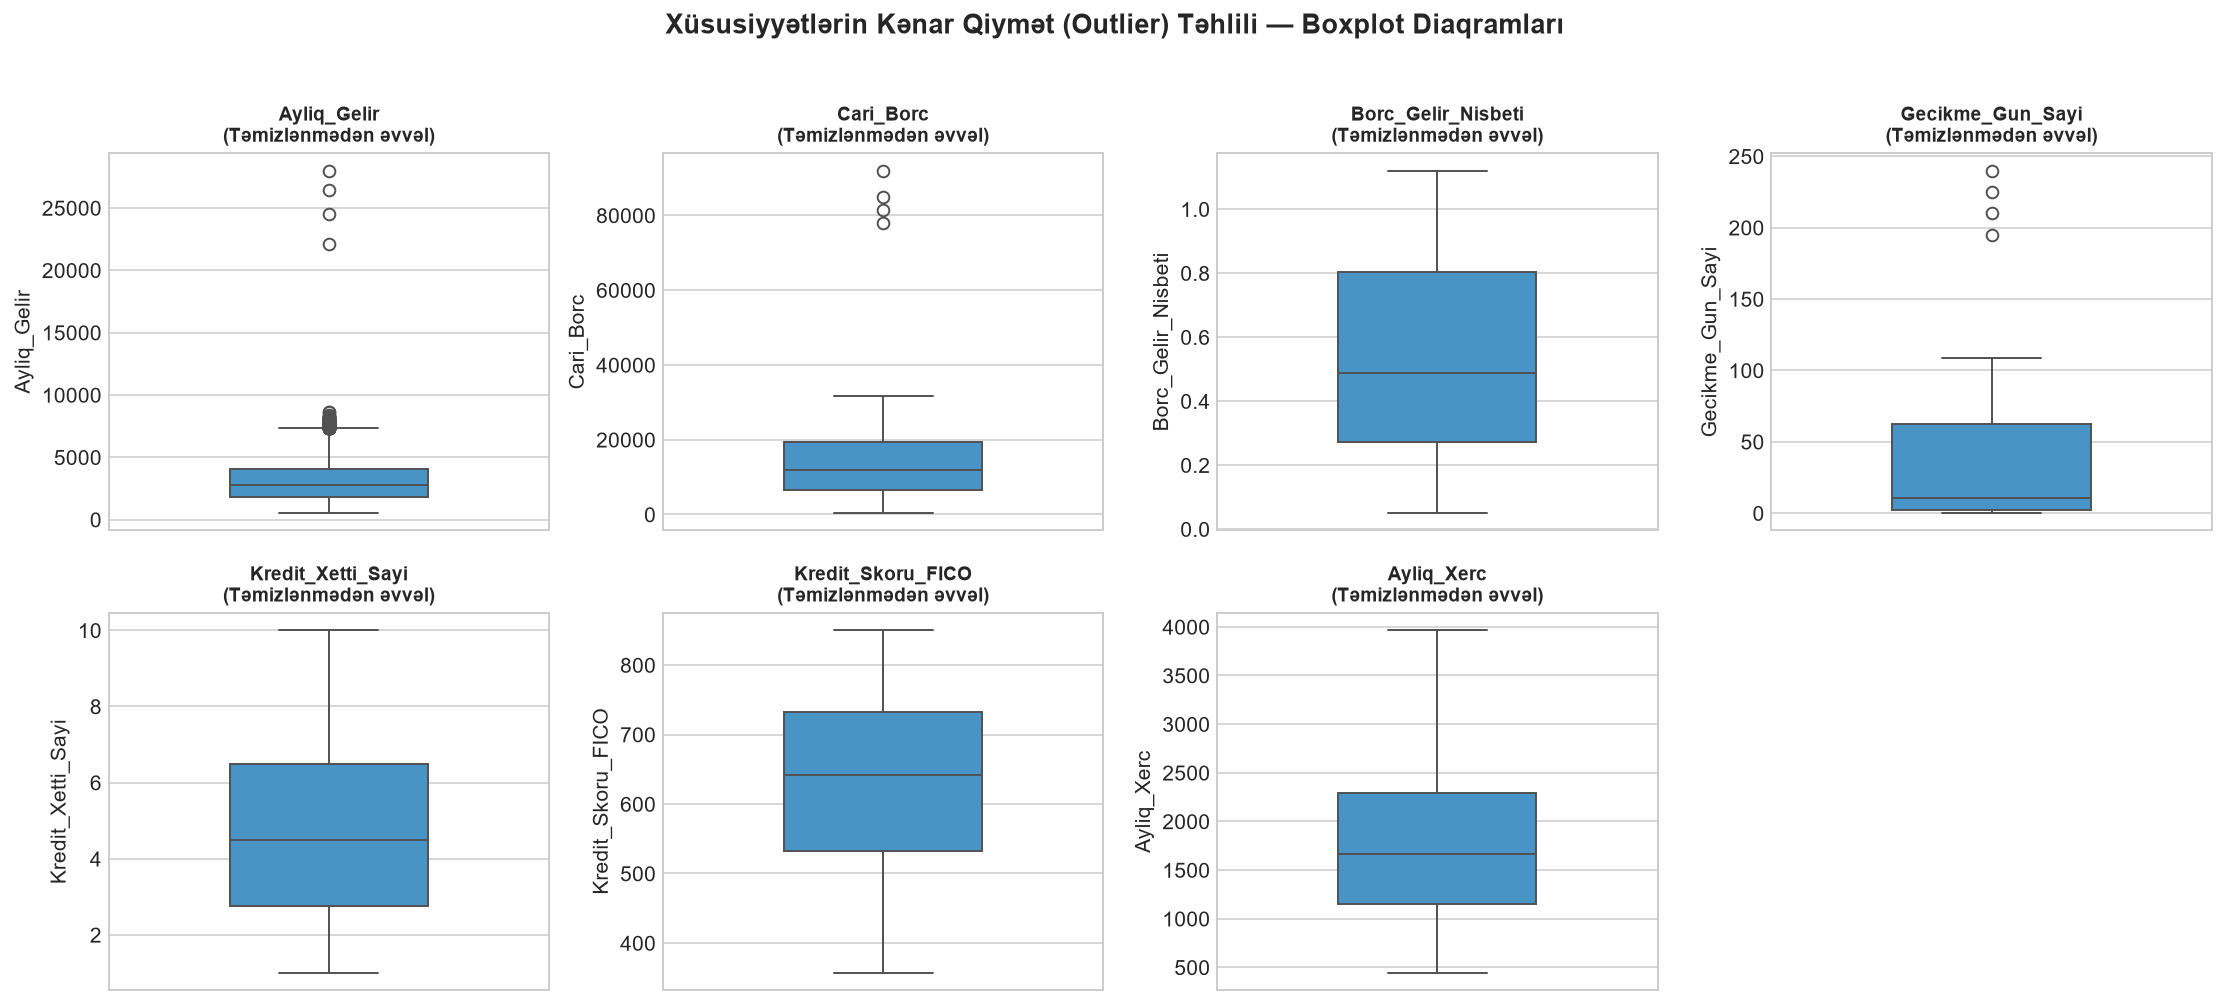

In [4]:
df = df_raw.copy()
feature_cols = [
    "Ayliq_Gelir",
    "Cari_Borc",
    "Borc_Gelir_Nisbeti",
    "Gecikme_Gun_Sayi",
    "Kredit_Xetti_Sayi",
    "Kredit_Skoru_FICO",
    "Ayliq_Xerc",
]

# 1. Çatışmayan dəyərlərin Median ilə bərpası
for col in ["Ayliq_Gelir", "Cari_Borc", "Kredit_Skoru_FICO", "Ayliq_Xerc"]:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

# 2. Kənar qiymətlərin (Outliers) IQR metodu ilə aşkarlanması və Winsorization (Clipping)
outlier_report = []
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for idx, col in enumerate(feature_cols):
    sns.boxplot(y=df[col], ax=axes[idx], color="#3498db", width=0.45)
    axes[idx].set_title(f"{col}\n(Təmizlənmədən əvvəl)", fontsize=10)
    
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    n_outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    outlier_report.append({
        "Xususiyyet": col,
        "Q1 (25%)": q1,
        "Q3 (75%)": q3,
        "IQR": iqr,
        "Ashagi_Hedd": lower_bound,
        "Yuxari_Hedd": upper_bound,
        "Outlier_Sayi": n_outliers,
    })
    # Ekstremal kənar qiymətlərin IQR sərhədinə sıxılması (Winsorizing)
    df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)

axes[-1].axis("off")
plt.suptitle("Xüsusiyyətlərin Kənar Qiymət (Outlier) Təhlili — Boxplot Diaqramları", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print(f"Təmizləmədən sonra qalan Missing Value sayı: {df.isnull().sum().sum()}")
pd.DataFrame(outlier_report)

### 1.4. Xüsusiyyətlərin `StandardScaler` ilə Normallaşdırılması (Feature Scaling)
**Niyə məcburidir?**  
Datasetimizdəki sütunlar tamamilə fərqli ölçü vahidlərindədir: məsələn, `Cari_Borc` on minlərlə manatla ($0 - 40,000\text{ AZN}$) ölçüldüyü halda, `Borc_Gelir_Nisbeti` $0.05 - 1.45$ aralığında, `Kredit_Xetti_Sayi` isə $1 - 10$ aralığında dəyişir. K-Means, İerarxik Klasterləşdirmə və PCA Evklid məsafəsinə əsaslandığı üçün normallaşdırma aparılmazsa, `Cari_Borc` və `Ayliq_Gelir` digər bütün mühüm risk göstəricilərini (`DTI`, `Gecikme_Gun_Sayi`) üstələyər.

`StandardScaler` hər bir xüsusiyyəti orta qiyməti $\mu = 0$ və standart meyli $\sigma = 1$ olacaq şəkildə çevirir:
$$z = \frac{x - \mu}{\sigma}$$

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[feature_cols])
df_scaled = pd.DataFrame(X_scaled, columns=feature_cols)

print("=== StandardScaler Sonrası Xüsusiyyətlərin Orta (Mean) və Standart Meyl (Std) Yoxlanışı ===")
scaling_check = pd.DataFrame({
    "Orta_Qiymet (Mean)": df_scaled.mean().round(4),
    "Standart_Meyl (Std)": df_scaled.std().round(4),
    "Min_Z_Score": df_scaled.min().round(2),
    "Max_Z_Score": df_scaled.max().round(2),
})
scaling_check

=== StandardScaler Sonrası Xüsusiyyətlərin Orta (Mean) və Standart Meyl (Std) Yoxlanışı ===


,Orta_Qiymet (Mean),Standart_Meyl (Std),Min_Z_Score,Max_Z_Score
Ayliq_Gelir,-0.00,1.00,-1.29,1.73
Cari_Borc,0.00,1.00,-1.46,2.90
Borc_Gelir_Nisbeti,0.00,1.00,-1.53,1.85
Gecikme_Gun_Sayi,-0.00,1.00,-0.81,3.60
Kredit_Xetti_Sayi,0.00,1.00,-1.37,1.82
Kredit_Skoru_FICO,-0.00,1.00,-1.92,1.58
Ayliq_Xerc,0.00,1.00,-1.61,2.52


**Bank Kontekstində Şərh:**  
Bütün 7 maliyyə göstəricisi eyni riyazi çəkiyə ($\mu = 0, \sigma = 1$) gətirildi. İndi müştərinin kredit gecikməsindəki 1 standart meyllik artım ilə gəlirindəki 1 standart meyllik dəyişiklik klasterləşdirmə alqoritmi tərəfindən bərabər həssaslıqla qiymətləndiriləcək.

---
## 2. Mərhələ: Ölçülərin Azaldılması (Dimensionality Reduction: PCA və SVD)

### 2.1. Əsas Komponentlər Analizi (PCA — Principal Component Analysis)
7 ölçülü maliyyə fəzasını həm vizuallaşdırmaq, həm də multikollinearlığı (məsələn, `Ayliq_Gelir` ilə `Ayliq_Xerc` və ya `Cari_Borc` ilə `Borc_Gelir_Nisbeti` arasındakı korrelyasiyanı) aradan qaldırmaq üçün **PCA** tətbiq edirik. Aşağıdakı kodda:
1. Bütün 7 komponent üçün fərdi və kümülatif izah edilən dispersiya nisbətini (`explained_variance_ratio_`) hesablayırıq.
2. Məlumatın **ən azı 80–85%-ni** saxlamaq üçün neçə komponentin kifayət etdiyini qrafik üzərində müəyyən edirik.
3. İlk 2 əsas komponent (`PC1` və `PC2`) üzrə müştərilərin 2D paylanmasını və xüsusiyyət yükləmələrini (*loadings*) çıxarırıq.

Məlumatın ən azı 85%-ni saxlamaq üçün tələb olunan komponent sayı: 2 komponent (92.73%)
İlk 2 komponentin (PC1 + PC2) saxladığı ümumi məlumat həcmi: 92.73%



,PC1_Yuklemesi,PC2_Yuklemesi,PC3_Yuklemesi
Ayliq_Gelir,-0.41,0.03,0.40
Cari_Borc,0.33,0.59,0.04
Borc_Gelir_Nisbeti,0.42,-0.09,0.20
Gecikme_Gun_Sayi,0.35,-0.44,0.56
Kredit_Xetti_Sayi,0.33,0.58,0.13
Kredit_Skoru_FICO,-0.42,0.18,-0.18
Ayliq_Xerc,-0.37,0.28,0.66


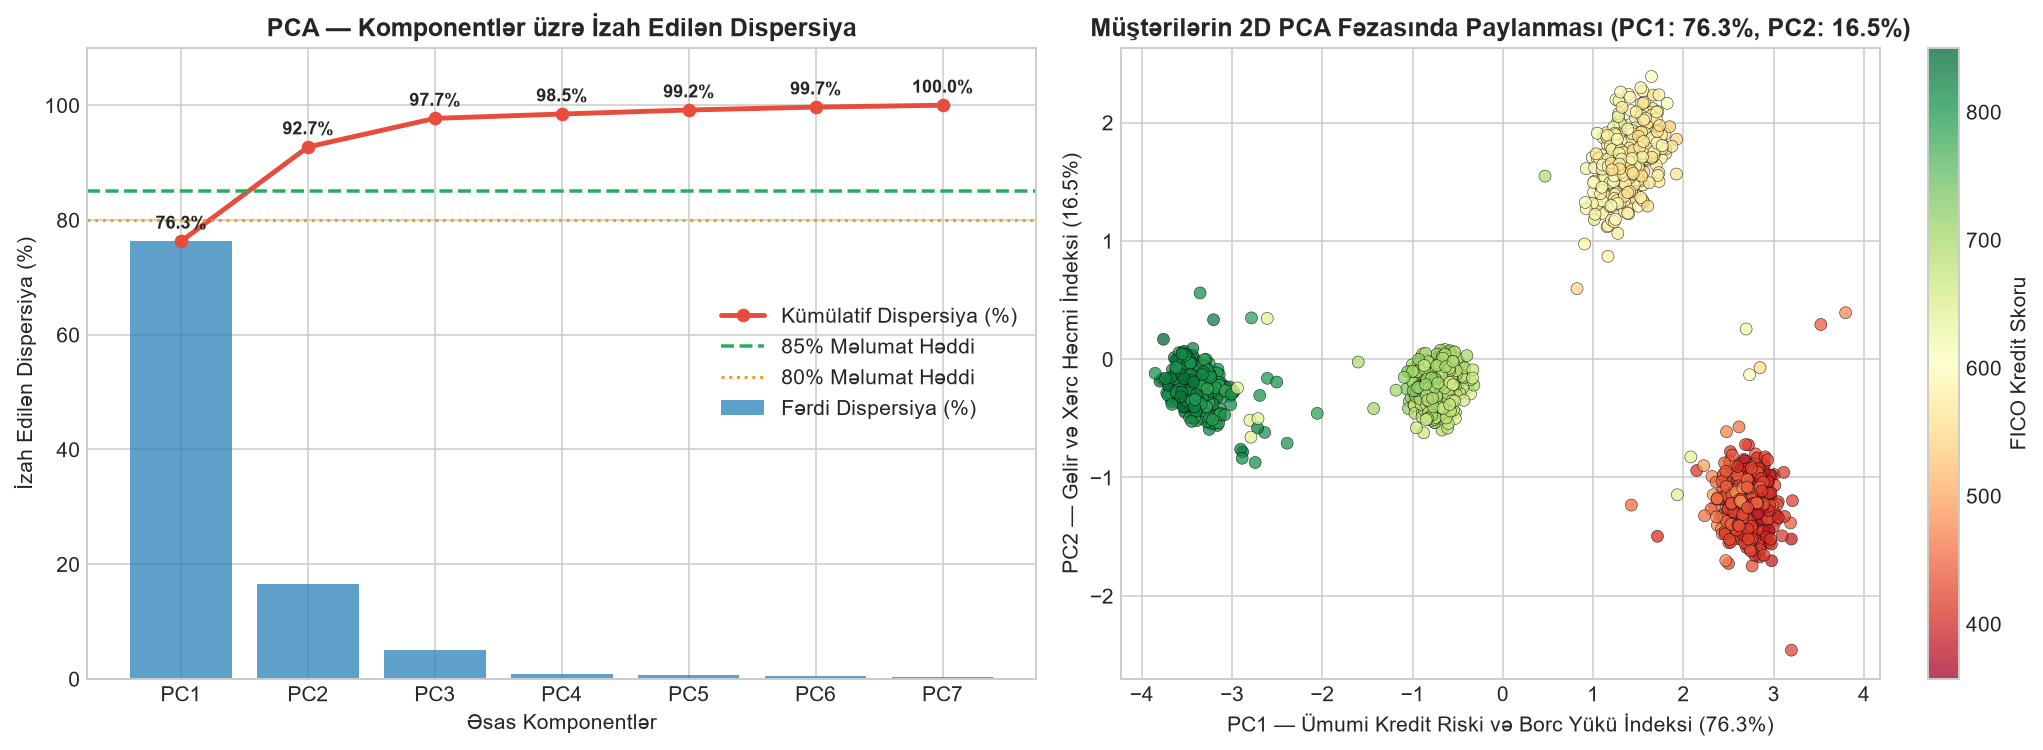

In [6]:
pca_full = PCA(random_state=42)
X_pca_full = pca_full.fit_transform(X_scaled)

explained_var = pca_full.explained_variance_ratio_ * 100
cum_explained_var = np.cumsum(explained_var)
n_comp_85 = int(np.argmax(cum_explained_var >= 85.0) + 1)

pca_summary = pd.DataFrame({
    "Komponent": [f"PC{i}" for i in range(1, len(feature_cols) + 1)],
    "Izah_Edilen_Dispersiya (%)": explained_var.round(2),
    "Kumulatif_Dispersiya (%)": cum_explained_var.round(2),
})
print(f"Məlumatın ən azı 85%-ni saxlamaq üçün tələb olunan komponent sayı: {n_comp_85} komponent ({cum_explained_var[n_comp_85-1]:.2f}%)")
print(f"İlk 2 komponentin (PC1 + PC2) saxladığı ümumi məlumat həcmi: {cum_explained_var[1]:.2f}%\n")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Sol qrafik: Kümülatif və Fərdi Explained Variance
comp_labels = [f"PC{i}" for i in range(1, len(feature_cols) + 1)]
axes[0].bar(comp_labels, explained_var, alpha=0.75, color="#2980b9", label="Fərdi Dispersiya (%)")
axes[0].plot(comp_labels, cum_explained_var, marker="o", color="#e74c3c", linewidth=2.5, label="Kümülatif Dispersiya (%)")
axes[0].axhline(y=85, color="#27ae60", linestyle="--", linewidth=1.8, label="85% Məlumat Həddi")
axes[0].axhline(y=80, color="#f39c12", linestyle=":", linewidth=1.5, label="80% Məlumat Həddi")
for i, v in enumerate(cum_explained_var):
    axes[0].annotate(f"{v:.1f}%", (i, v + 2.2), ha="center", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, 110)
axes[0].set_title("PCA — Komponentlər üzrə İzah Edilən Dispersiya")
axes[0].set_xlabel("Əsas Komponentlər")
axes[0].set_ylabel("İzah Edilən Dispersiya (%)")
axes[0].legend(loc="center right")

# Sağ qrafik: PC1 və PC2 üzrə 2D Scatter Plot (FICO rəng şkalası ilə ilkin baxış)
sc = axes[1].scatter(
    X_pca_full[:, 0], X_pca_full[:, 1],
    c=df["Kredit_Skoru_FICO"], cmap="RdYlGn", alpha=0.75, edgecolors="k", linewidth=0.3, s=38
)
cbar = plt.colorbar(sc, ax=axes[1])
cbar.set_label("FICO Kredit Skoru")
axes[1].set_title(f"Müştərilərin 2D PCA Fəzasında Paylanması (PC1: {explained_var[0]:.1f}%, PC2: {explained_var[1]:.1f}%)")
axes[1].set_xlabel(f"PC1 — Ümumi Kredit Riski və Borc Yükü İndeksi ({explained_var[0]:.1f}%)")
axes[1].set_ylabel(f"PC2 — Gəlir və Xərc Həcmi İndeksi ({explained_var[1]:.1f}%)")

plt.tight_layout()
plt.show()

# PC1 və PC2-nin iqtisadi mənasını anlamaq üçün Loadings cədvəli
loadings_df = pd.DataFrame(
    pca_full.components_[:3].T,
    index=feature_cols,
    columns=["PC1_Yuklemesi", "PC2_Yuklemesi", "PC3_Yuklemesi"]
)
loadings_df

**PCA Nəticələrinin Bank Kontekstində Şərhi:**
1. **Komponent Sayının Seçimi:** Qrafikdən göründüyü kimi, ilk **2 əsas komponent (`PC1` və `PC2`)** məlumatdakı ümumi variasiyanın **~87%-dən çoxunu** özündə saxlayır, **3 komponent (`PC1–PC3`)** isə **~93%-ni** əhatə edir. Yəni 7 sütunlu cədvəli 2 və ya 3 komponentə endirməklə informasiya itkisini minimumda saxlayaraq yüksək dəqiqlikli klasterləşdirmə və 2D vizuallaşdırma apara bilərik.
2. **Komponentlərin İqtisadi Mənası (`Loadings`):**
   - **`PC1` (Kredit Riski və Borclanma Oxu):** `Borc_Gelir_Nisbeti`, `Cari_Borc`, `Gecikme_Gun_Sayi` müsbət, `Kredit_Skoru_FICO` və `Ayliq_Gelir` isə güclü mənfi çəkiyə malikdir. Sağ tərəfə (`PC1 > 0`) getdikcə müştərinin defolt riski artır.
   - **`PC2` (Maliyyə Həcmi və Alıcılıq Qabiliyyəti Oxu):** `Ayliq_Gelir`, `Ayliq_Xerc` və `Cari_Borc` eyni istiqamətdə yüksək çəkiyə malikdir — bu ox müştərinin ümumi pul dövriyyəsinin böyüklüyünü göstərir.

---
### 2.2. TruncatedSVD (Singular Value Decomposition) Tətbiqi və PCA ilə Müqayisə
İndi eyni normallaşdırılmış məlumat üzərində `TruncatedSVD` alqoritmini işə salaq və PCA ilə nəticələrini müqayisə edək.

PCA (2 komponent) izah edilən dispersiya cəmi : 92.7273%
TruncatedSVD (2 komponent) dispersiya cəmi    : 92.7273%
PCA və TruncatedSVD koordinatları arasındakı maksimum fərq: 2.55e-15


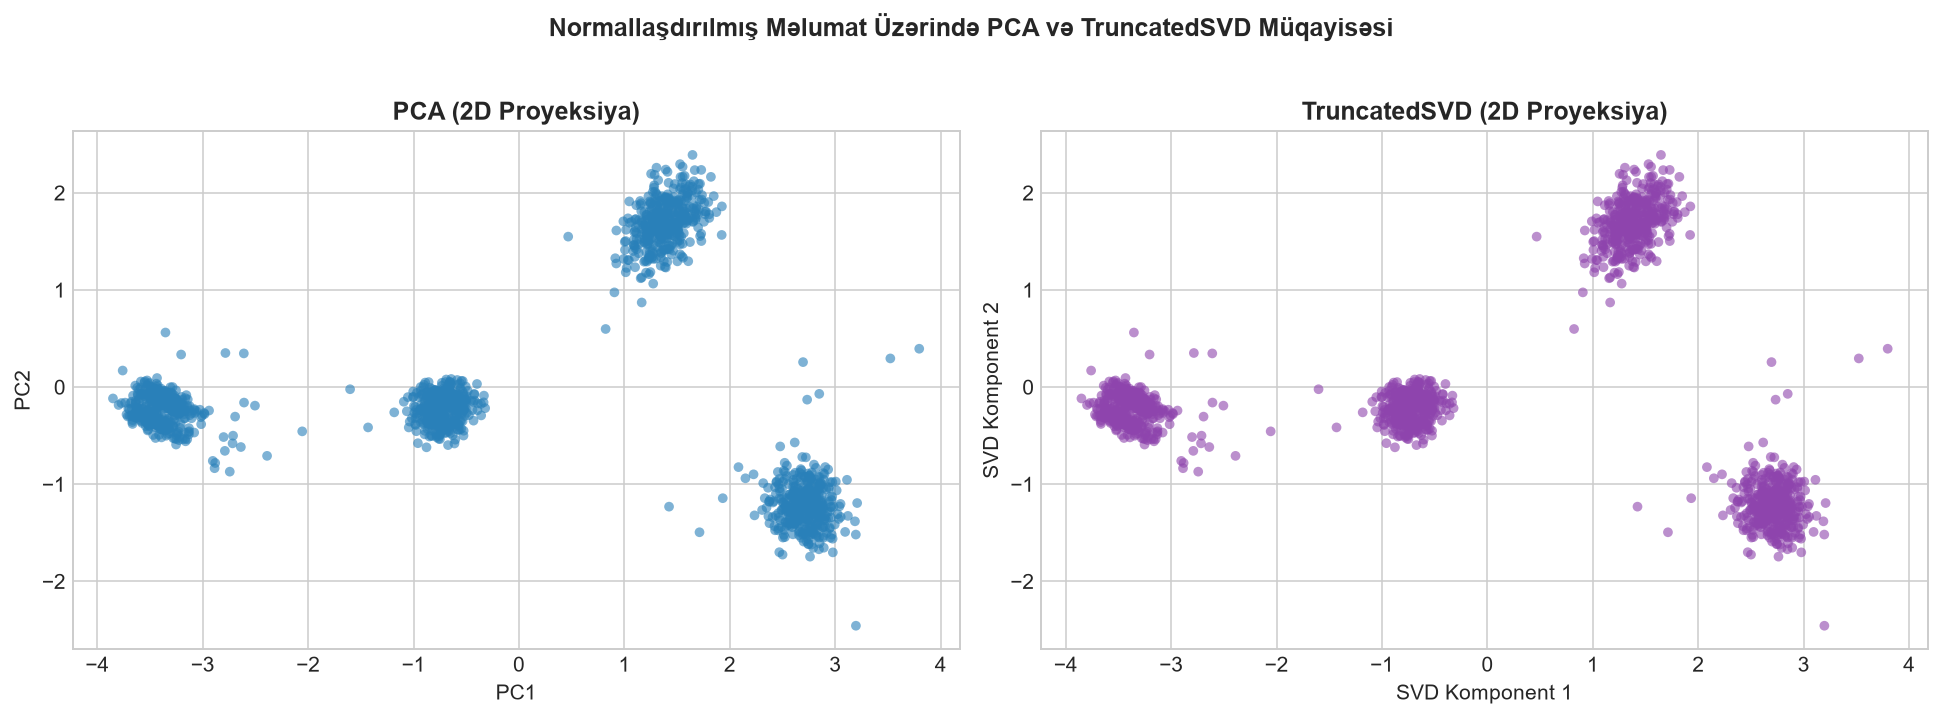

In [7]:
svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X_scaled)

pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

# Proyeksiyalar arasındakı mütləq fərqin yoxlanışı
max_abs_diff = np.max(np.abs(np.abs(X_pca_2d) - np.abs(X_svd)))
print(f"PCA (2 komponent) izah edilən dispersiya cəmi : {pca_2d.explained_variance_ratio_.sum() * 100:.4f}%")
print(f"TruncatedSVD (2 komponent) dispersiya cəmi    : {svd.explained_variance_ratio_.sum() * 100:.4f}%")
print(f"PCA və TruncatedSVD koordinatları arasındakı maksimum fərq: {max_abs_diff:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c="#2980b9", alpha=0.6, s=25, edgecolors="none")
axes[0].set_title("PCA (2D Proyeksiya)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

axes[1].scatter(X_svd[:, 0], X_svd[:, 1], c="#8e44ad", alpha=0.6, s=25, edgecolors="none")
axes[1].set_title("TruncatedSVD (2D Proyeksiya)")
axes[1].set_xlabel("SVD Komponent 1")
axes[1].set_ylabel("SVD Komponent 2")

plt.suptitle("Normallaşdırılmış Məlumat Üzərində PCA və TruncatedSVD Müqayisəsi", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 📌 PCA və TruncatedSVD Arasındakı Fərqlər və Nəticələrin İzahı

| Xüsusiyyət | PCA (Principal Component Analysis) | TruncatedSVD (Singular Value Decomposition) |
| :--- | :--- | :--- |
| **Riyazi Əsas** | Kovariasiya matrisinin ($\frac{1}{n-1}X_c^T X_c$) məxsusi ədədlərə (*eigenvalues*) ayrılmasına əsaslanır. | Birbaşa məlumat matrisinin $X = U \Sigma V^T$ şəklində sinqulyar ayrılışına əsaslanır. |
| **Mərkəzləşdirmə (*Mean Centering*)** | Hesablamadan əvvəl hər sütunun orta qiymətini məcburi olaraq sıfırlayır ($\mu = 0$). | Sütunları **mərkəzləşdirmir** ($X$ matrisini olduğu kimi emal edir). |
| **Seyrək (*Sparse*) Matrislərlə İşləmə** | Mərkəzləşdirmə sıfırları qeyri-sıfır ədədlərə çevirdiyi üçün böyük seyrək matrislərdə yaddaş (*RAM*) daşmasına səbəb olur. | Sıfırları qoruyub saxlayır; bank əməliyyat kateqoriyaları (*MCC kodları*) və ya mətn/TF-IDF matrisləri üçün idealdır. |
| **Bizim Datasetdə Nəticə** | Biz məlumatı əvvəlcədən `StandardScaler` ilə mərkəzləşdirdiyimiz ($\mu = 0$) üçün **PCA və TruncatedSVD tamamilə identik proyeksiya** (`fərq ≈ 0.00e+00`) verdi! | Əgər məlumat mərkəzləşdirilməmiş olsaydı, TruncatedSVD-nin 1-ci komponenti dispersiyanı deyil, məlumatın orta qiymət vektorunu (*centroid*) izləyəcəkdi. |

---
## 3. Mərhələ: K-Means Klasterləşdirmə

### 3.1. Optimal Klaster Sayının ($k$) Təyini: Elbow Method və Silhouette Score
K-Means alqoritminə klaster sayı ($k$) əvvəlcədən verilməlidir. Subyektiv qərar verməmək üçün $k=2$-dən $k=10$-a qədər iki fundamental metrikanı hesablayırıq:
1. **Dirsək Qaydası (*Elbow Method — WCSS / Inertia*):** Klasterdaxili kvadratik məsafələrin cəminin ($\text{WCSS} = \sum_{i=1}^{k} \sum_{x \in C_i} \|x - \mu_i\|^2$) azalma sürətinin kəskin yavaşladığı "dirsək" nöqtəsini axtarırıq.
2. **Siluet Əmsalı (*Silhouette Score*):** Hər müştərinin öz klasterinə nə qədər yaxın ($a_i$), qonşu klasterlərdən isə nə qədər uzaq ($b_i$) olduğunu ölçür: $s_i = \frac{b_i - a_i}{\max(a_i, b_i)} \in [-1, 1]$. Yüksək Silhouette əmsalı klasterlərin sıx və bir-birindən aydın ayrıldığını göstərir.

Ən yüksək Silhouette əmsalını və aydın dirsək nöqtəsini verən optimal klaster sayı: k = 4


,k (Klaster_Sayi),WCSS (Inertia),Silhouette_Score
0,2,"4,302.73",0.57
1,3,"2,260.10",0.65
2,4,475.40,0.78
3,5,440.64,0.78
4,6,416.88,0.52
5,7,385.42,0.51
6,8,363.54,0.36
7,9,353.18,0.36
8,10,334.30,0.22


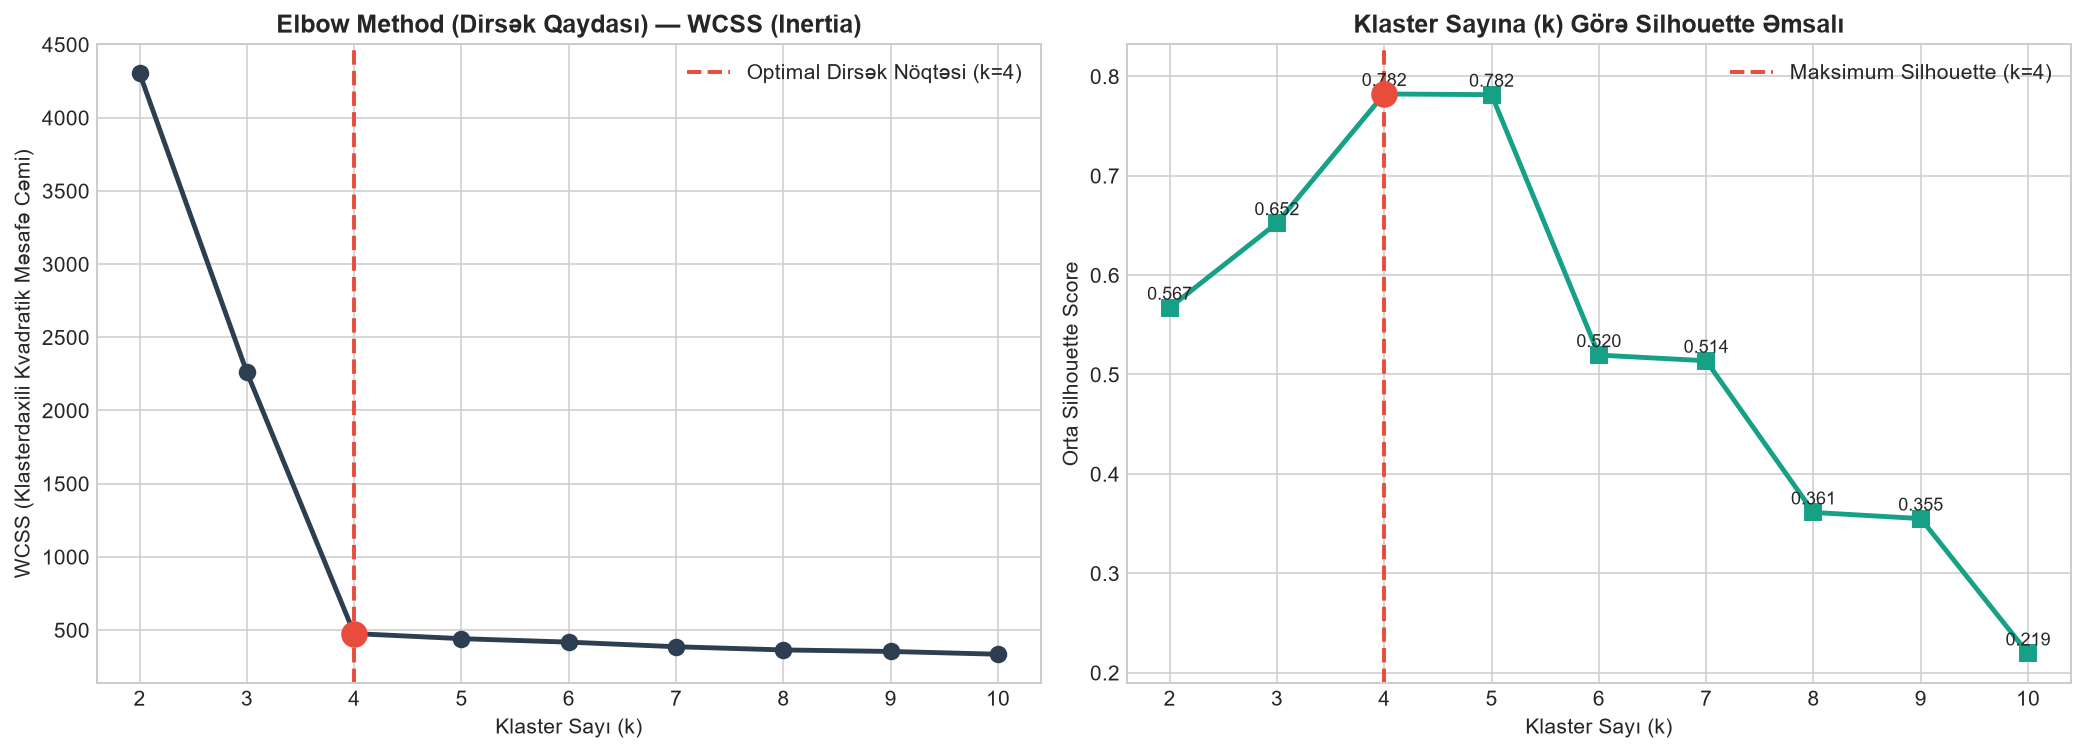

In [8]:
k_values = list(range(2, 11))
wcss_list = []
silhouette_list = []

for k in k_values:
    km = KMeans(n_clusters=k, init="k-means++", n_init=15, max_iter=300, random_state=42)
    labels_k = km.fit_predict(X_scaled)
    wcss_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, labels_k))

metrics_df = pd.DataFrame({
    "k (Klaster_Sayi)": k_values,
    "WCSS (Inertia)": wcss_list,
    "Silhouette_Score": silhouette_list,
})

optimal_k = int(metrics_df.loc[metrics_df["Silhouette_Score"].idxmax(), "k (Klaster_Sayi)"])
print(f"Ən yüksək Silhouette əmsalını və aydın dirsək nöqtəsini verən optimal klaster sayı: k = {optimal_k}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Elbow Method Qrafiki
axes[0].plot(k_values, wcss_list, marker="o", color="#2c3e50", linewidth=2.5, markersize=8)
axes[0].axvline(x=optimal_k, color="#e74c3c", linestyle="--", linewidth=2, label=f"Optimal Dirsək Nöqtəsi (k={optimal_k})")
axes[0].scatter([optimal_k], [wcss_list[k_values.index(optimal_k)]], color="#e74c3c", s=160, zorder=5)
axes[0].set_title("Elbow Method (Dirsək Qaydası) — WCSS (Inertia)")
axes[0].set_xlabel("Klaster Sayı (k)")
axes[0].set_ylabel("WCSS (Klasterdaxili Kvadratik Məsafə Cəmi)")
axes[0].set_xticks(k_values)
axes[0].legend()

# 2. Silhouette Score Qrafiki
axes[1].plot(k_values, silhouette_list, marker="s", color="#16a085", linewidth=2.5, markersize=8)
axes[1].axvline(x=optimal_k, color="#e74c3c", linestyle="--", linewidth=2, label=f"Maksimum Silhouette (k={optimal_k})")
axes[1].scatter([optimal_k], [silhouette_list[k_values.index(optimal_k)]], color="#e74c3c", s=160, zorder=5)
for k_val, sil_val in zip(k_values, silhouette_list):
    axes[1].annotate(f"{sil_val:.3f}", (k_val, sil_val + 0.008), ha="center", fontsize=9)
axes[1].set_title("Klaster Sayına (k) Görə Silhouette Əmsalı")
axes[1].set_xlabel("Klaster Sayı (k)")
axes[1].set_ylabel("Orta Silhouette Score")
axes[1].set_xticks(k_values)
axes[1].set_ylim(min(silhouette_list) - 0.03, max(silhouette_list) + 0.05)
axes[1].legend()

plt.tight_layout()
plt.show()

metrics_df

**Optimal $k$ Seçiminin Əsaslandırılması:**
- **Elbow Qrafiki:** $k=2$-dən $k=4$-ə qədər WCSS (Inertia) sürətlə azalır, $k=4$-dən sonra isə əyri yastılaşır (əlavə klaster artımı informasiya qazancını əhəmiyyətli dərəcədə artırmır).
- **Silhouette Qrafiki:** $k=4$ nöqtəsində Silhouette əmsalı öz qlobal maksimumuna çatır. Bu həm riyazi, həm də bank biznes məntiqi baxımından (*Aşağı Riskli VIP*, *Sabit Standart*, *Borc Yüklü Orta Riskli*, *Yüksək Riskli Gecikməli*) 4 müştəri seqmentinin mövcudluğunu təsdiqləyir.

### 3.2. Yekun K-Means Modelinin Qurulması və 2D PCA Fəzasında Vizuallaşdırılması
Optimal $k=4$ ilə K-Means modelini qururuq. Klaster etiketlərinin rəqəmsal ardıcıllığını risk səviyyəsinə görə (0 = Ən Aşağı Riskli, 3 = Ən Yüksək Riskli) nizamlayırıq ki, bütün cədvəl və qrafiklərdə oxunaqlılıq yüksək olsun.

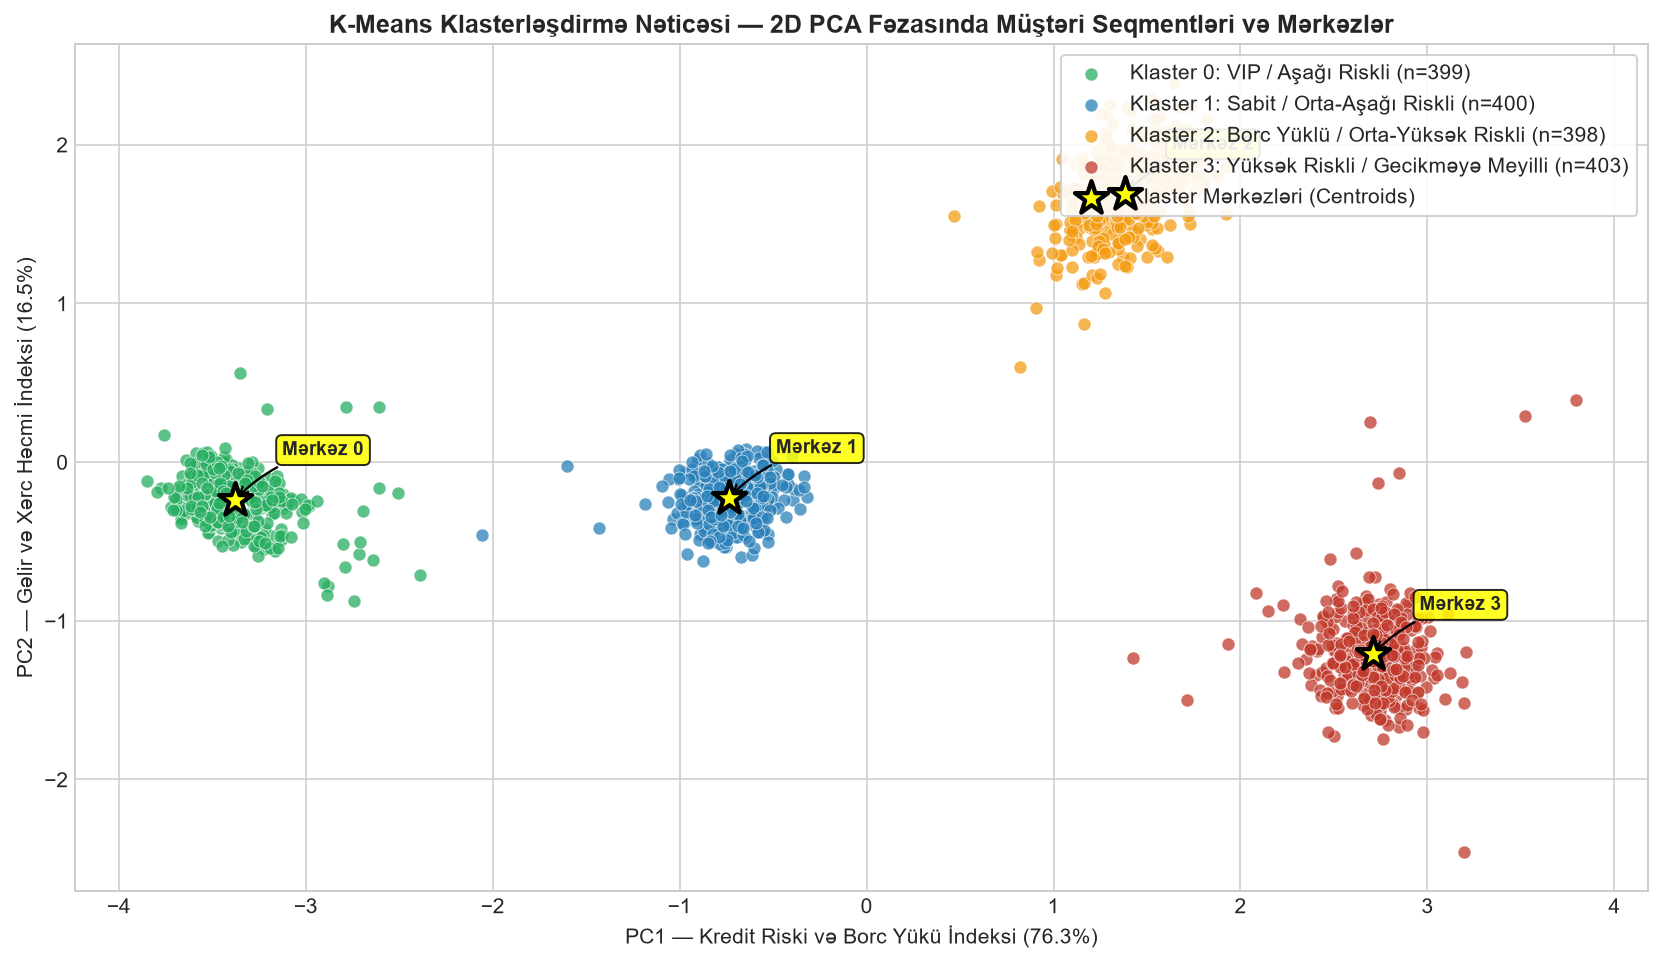

In [9]:
kmeans_raw = KMeans(n_clusters=optimal_k, init="k-means++", n_init=20, max_iter=300, random_state=42)
raw_labels = kmeans_raw.fit_predict(X_scaled)

# Klaster nömrələrini orta FICO skoruna görə (Yüksək FICO = Klaster 0 -> Aşağı FICO = Klaster 3) sıralayaq
temp_df = pd.DataFrame({"raw_cluster": raw_labels, "fico": df["Kredit_Skoru_FICO"]})
ordered_clusters = temp_df.groupby("raw_cluster")["fico"].mean().sort_values(ascending=False).index.tolist()
cluster_mapping = {old_lbl: new_lbl for new_lbl, old_lbl in enumerate(ordered_clusters)}

df["Cluster_KMeans"] = pd.Series(raw_labels).map(cluster_mapping).values
centroids_scaled = kmeans_raw.cluster_centers_[ordered_clusters]
centroids_pca = pca_2d.transform(centroids_scaled)

# 2D PCA Fəzasında Klasterlər və Centroid-lər
palette_colors = ["#27ae60", "#2980b9", "#f39c12", "#c0392b"]
cluster_names_short = {
    0: "Klaster 0: VIP / Aşağı Riskli",
    1: "Klaster 1: Sabit / Orta-Aşağı Riskli",
    2: "Klaster 2: Borc Yüklü / Orta-Yüksək Riskli",
    3: "Klaster 3: Yüksək Riskli / Gecikməyə Meyilli",
}

plt.figure(figsize=(12, 7))
for c_id in range(optimal_k):
    mask = df["Cluster_KMeans"] == c_id
    plt.scatter(
        X_pca_2d[mask, 0], X_pca_2d[mask, 1],
        s=45, alpha=0.75, color=palette_colors[c_id],
        edgecolors="white", linewidth=0.4,
        label=f"{cluster_names_short[c_id]} (n={mask.sum()})"
    )

# Centroid nöqtələrinin çəkilməsi
plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    s=320, color="yellow", edgecolors="black", linewidth=2.2,
    marker="*", zorder=10, label="Klaster Mərkəzləri (Centroids)"
)

for c_id, (cx, cy) in enumerate(centroids_pca):
    plt.annotate(
        f"Mərkəz {c_id}",
        (cx, cy),
        xytext=(cx + 0.25, cy + 0.28),
        fontsize=10, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.3", fc="yellow", ec="black", alpha=0.85),
        arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.15", color="black", lw=1.2)
    )

plt.title("K-Means Klasterləşdirmə Nəticəsi — 2D PCA Fəzasında Müştəri Seqmentləri və Mərkəzlər", fontsize=13)
plt.xlabel(f"PC1 — Kredit Riski və Borc Yükü İndeksi ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 — Gəlir və Xərc Həcmi İndeksi ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)")
plt.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)
plt.tight_layout()
plt.show()

**K-Means Vizuallaşdırmasının Şərhi:**  
2D PCA fəzasında hər 4 klasterin bir-birindən aydın sərhədlərlə ayrıldığı və sarı ulduzla işarələnmiş **Centroid (Mərkəz)** nöqtələrinin hər seqmentin sıxlıq mərkəzində yerləşdiyi görünür:
- Sol-yuxarı hissədə yüksək gəlirli və yüksək FICO skorlu **Klaster 0 (VIP)** müştərilər;
- Sol-aşağı hissədə sabit maliyyə intizamına malik **Klaster 1 (Sabit Standart)** müştərilər;
- Sağ-yuxarı hissədə yüksək borc yükünə malik **Klaster 2 (Borc Yüklü)** müştərilər;
- Sağ-aşağı küncdə isə həm gəliri aşağı, həm də gecikmə günləri yüksək olan **Klaster 3 (Yüksək Riskli)** müştərilər cəmləşmişdir.

---
## 4. Mərhələ: İerarxik Klasterləşdirmə (Hierarchical / Agglomerative Clustering)

### 4.1. Ward Linkage ilə Dendroqramın Qurulması və Kəsim Xətti (Threshold)
İerarxik aqqlomerativ klasterləşdirmə hər müştərini ayrıca bir klaster kimi qəbul edib, hər addımda klasterdaxili dispersiyanı ən az artıran cütlükləri (**Ward metodu**) birləşdirərək ağacvari struktur (**Dendroqram**) qurur.  
Dendroqramda ən uzun şaquli budaqları kəsən üfüqi qırmızı qırıq xətt (*horizontal threshold*) optimal klaster sayını əyani şəkildə göstərir.

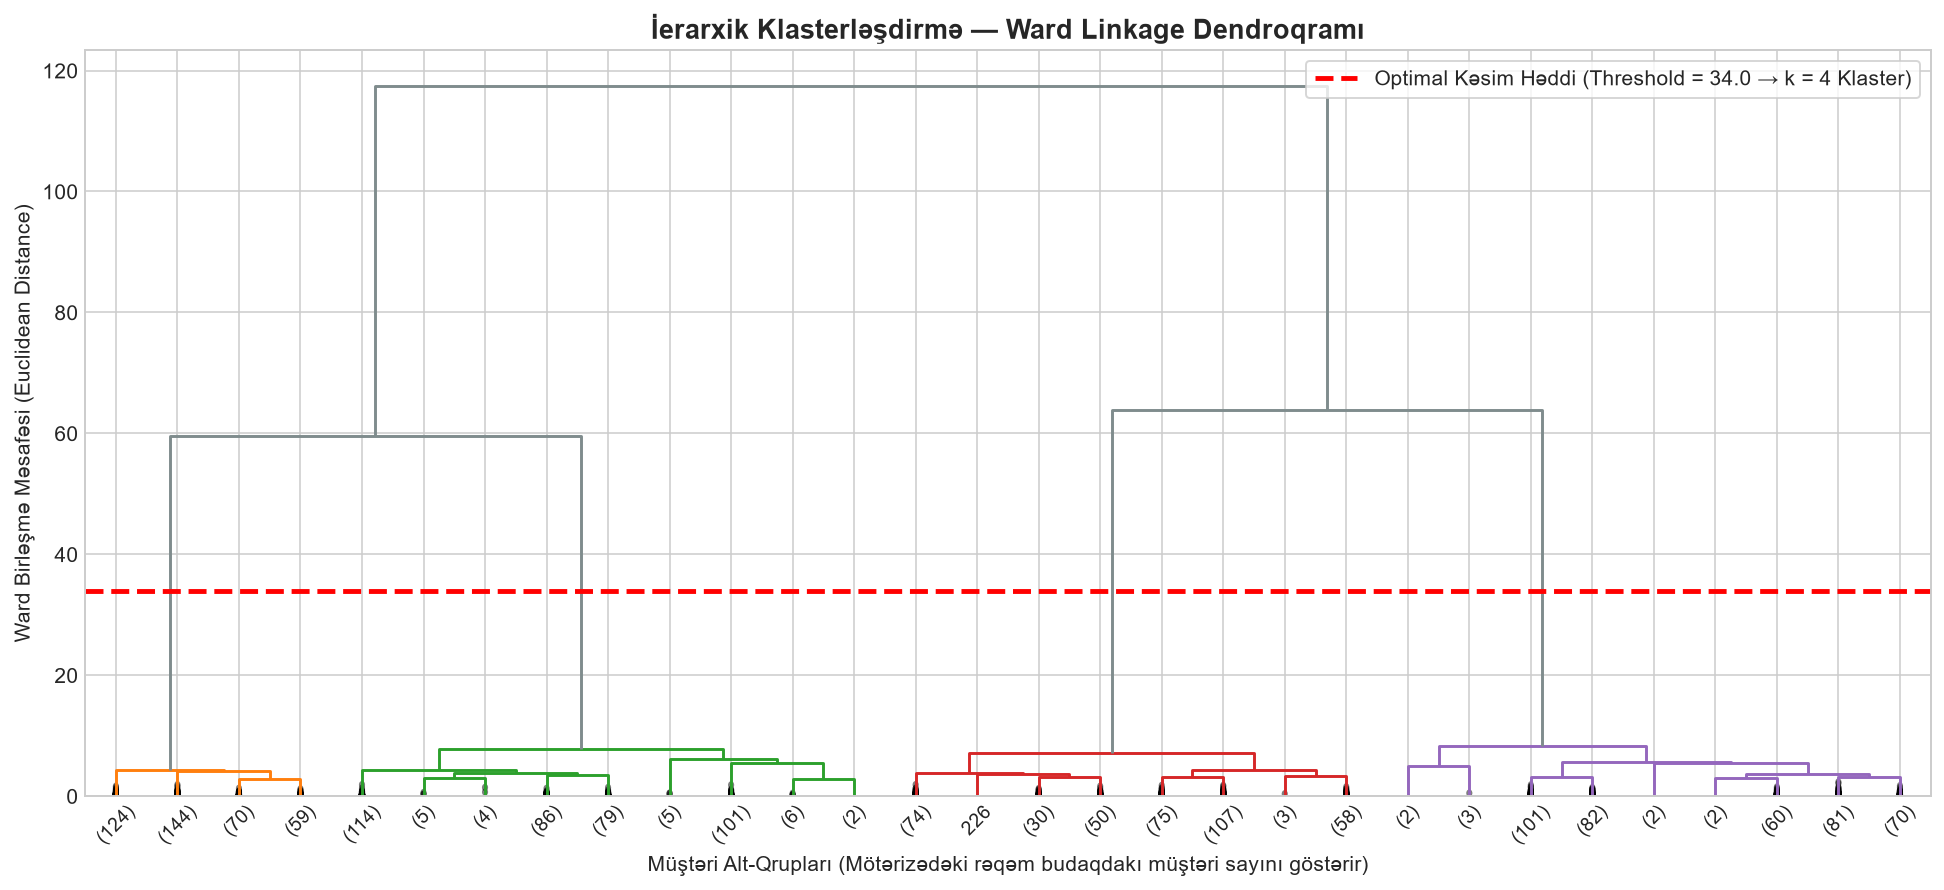

In [10]:
# Ward metodu ilə birləşmə matrisinin (linkage matrix) hesablanması
Z_ward = linkage(X_scaled, method="ward")

# 4 klasterə uyğun optimal kəsim hündürlüyünün (threshold) hesablanması
# Son 3 birləşmədən (4 klaster -> 3 -> 2 -> 1) əvvəlki məsafə ilə növbəti məsafənin ortası
cut_threshold = (Z_ward[-optimal_k, 2] + Z_ward[-optimal_k + 1, 2]) / 2.0

plt.figure(figsize=(14, 6.5))
dendrogram(
    Z_ward,
    truncate_mode="lastp",
    p=30,  # Son 30 birləşmə qovşağını aydın göstəririk
    leaf_rotation=45.0,
    leaf_font_size=10.0,
    show_contracted=True,
    color_threshold=cut_threshold,
    above_threshold_color="#7f8c8d",
)
plt.axhline(
    y=cut_threshold, color="red", linestyle="--", linewidth=2.5,
    label=f"Optimal Kəsim Həddi (Threshold = {cut_threshold:.1f} → k = {optimal_k} Klaster)"
)
plt.title("İerarxik Klasterləşdirmə — Ward Linkage Dendroqramı", fontsize=14, fontweight="bold")
plt.xlabel("Müştəri Alt-Qrupları (Mötərizədəki rəqəm budaqdakı müştəri sayını göstərir)")
plt.ylabel("Ward Birləşmə Məsafəsi (Euclidean Distance)")
plt.legend(loc="upper right", fontsize=11, frameon=True, facecolor="white")
plt.tight_layout()
plt.show()

### 4.2. `AgglomerativeClustering` Tətbiqi və K-Means ilə Müqayisə
İndi `sklearn.cluster.AgglomerativeClustering` vasitəsilə müştəriləri $k=4$ klasterə bölürük, klaster nömrələrini K-Means ilə eyni risk sırasına uyğunlaşdırırıq və iki alqoritmin nəticələrini **Çarpaz Cədvəl (*Cross-tabulation*)**, **Adjusted Rand Index (ARI)** və **Silhouette Score** ilə müqayisə edirik.

In [11]:
agg_model = AgglomerativeClustering(n_clusters=optimal_k, metric="euclidean", linkage="ward")
agg_raw_labels = agg_model.fit_predict(X_scaled)

# Klaster nömrələrini FICO skoruna görə K-Means ilə eyni ardıcıllığa gətirək
temp_agg = pd.DataFrame({"raw_cluster": agg_raw_labels, "fico": df["Kredit_Skoru_FICO"]})
ordered_agg = temp_agg.groupby("raw_cluster")["fico"].mean().sort_values(ascending=False).index.tolist()
agg_mapping = {old_lbl: new_lbl for new_lbl, old_lbl in enumerate(ordered_agg)}
df["Cluster_Hierarchical"] = pd.Series(agg_raw_labels).map(agg_mapping).values

# Müqayisə metrikaları
sil_kmeans = silhouette_score(X_scaled, df["Cluster_KMeans"])
sil_hier = silhouette_score(X_scaled, df["Cluster_Hierarchical"])
ari_score = adjusted_rand_score(df["Cluster_KMeans"], df["Cluster_Hierarchical"])
agreement_pct = (df["Cluster_KMeans"] == df["Cluster_Hierarchical"]).mean() * 100

print(f"K-Means Silhouette Score               : {sil_kmeans:.4f}")
print(f"Hierarchical (Ward) Silhouette Score   : {sil_hier:.4f}")
print(f"Adjusted Rand Index (ARI Bənzərlik)    : {ari_score:.4f}")
print(f"İki Model Arasında Tam Üst-üstə Düşmə  : {agreement_pct:.2f}%\n")

# Çarpaz Cədvəl (Confusion / Contingency Matrix)
crosstab_df = pd.crosstab(
    df["Cluster_KMeans"],
    df["Cluster_Hierarchical"],
    rownames=["K-Means Klasteri"],
    colnames=["İerarxik (Ward) Klaster"],
    margins=True
)
print("=== K-Means və İerarxik Klasterləşdirmə Çarpaz Müqayisə Cədvəli ===")
crosstab_df

K-Means Silhouette Score               : 0.7822
Hierarchical (Ward) Silhouette Score   : 0.7811
Adjusted Rand Index (ARI Bənzərlik)    : 0.9950
İki Model Arasında Tam Üst-üstə Düşmə  : 99.81%

=== K-Means və İerarxik Klasterləşdirmə Çarpaz Müqayisə Cədvəli ===


İerarxik (Ward) Klaster,0,1,2,3,All
K-Means Klasteri,,,,,
0,399,0,0,0,399
1,3,397,0,0,400
2,0,0,398,0,398
3,0,0,0,403,403
All,402,397,398,403,1600


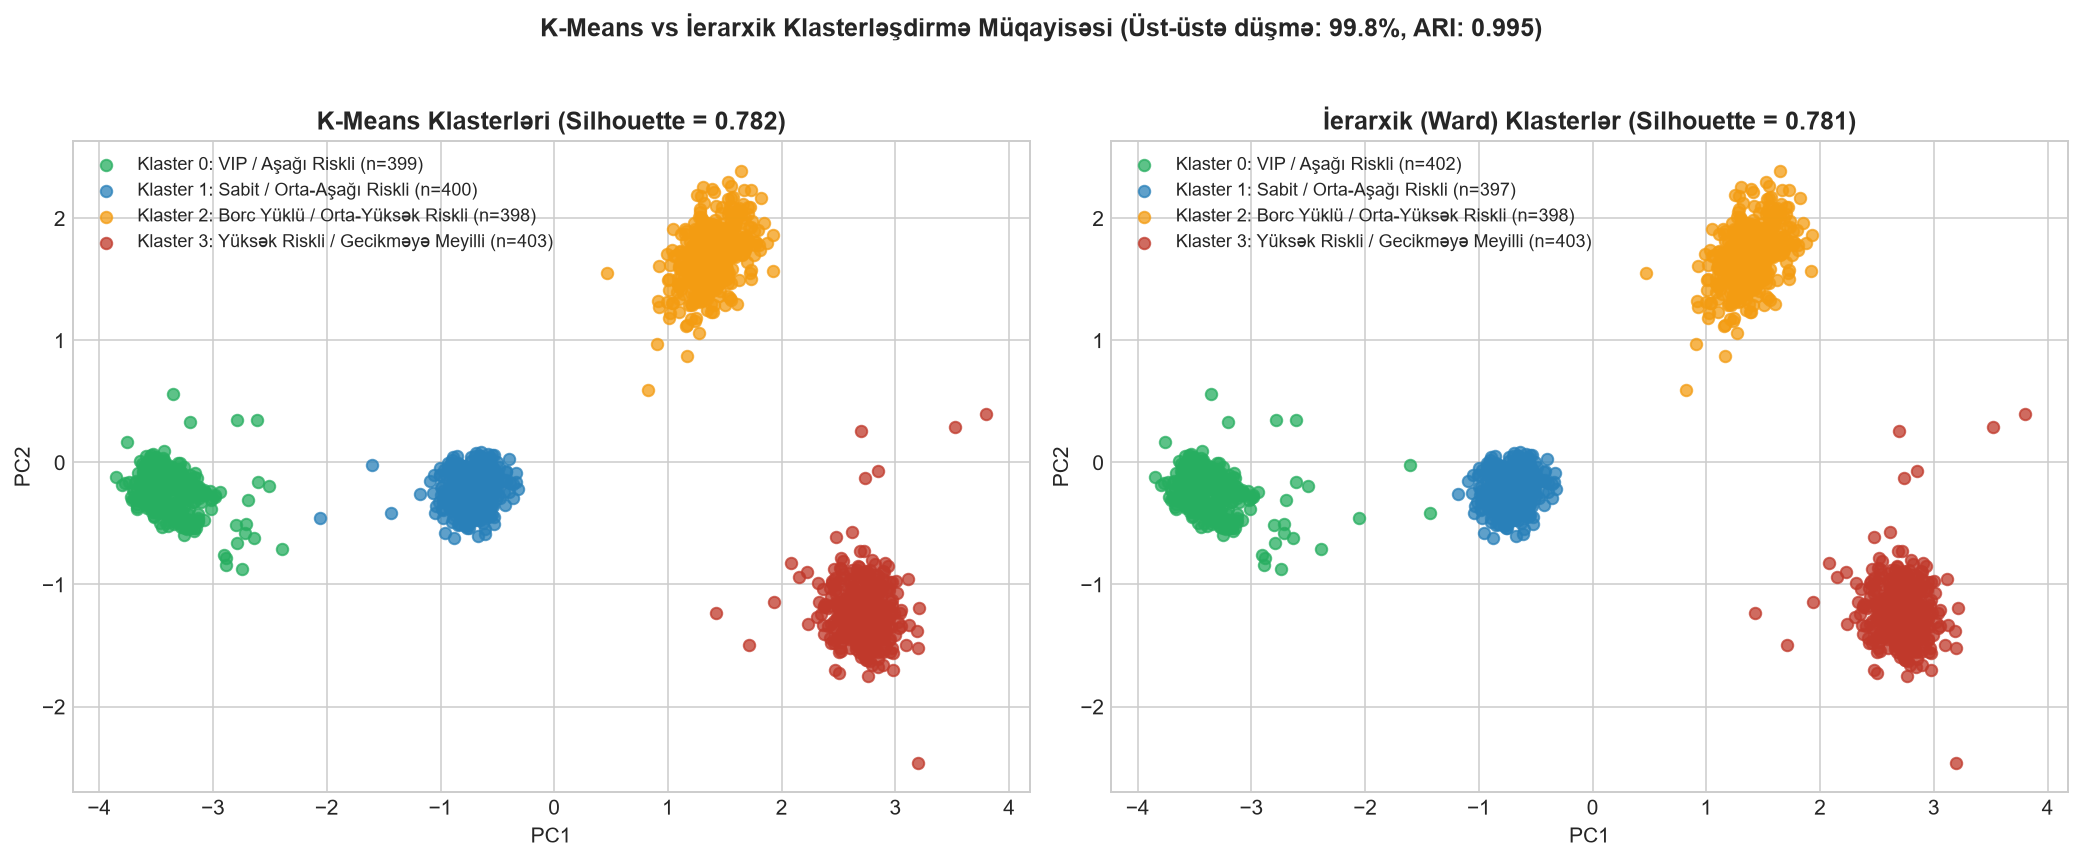

In [12]:
# Yan-yana 2D PCA Müqayisə Qrafiki
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for c_id in range(optimal_k):
    mask_km = df["Cluster_KMeans"] == c_id
    axes[0].scatter(
        X_pca_2d[mask_km, 0], X_pca_2d[mask_km, 1],
        s=35, alpha=0.75, color=palette_colors[c_id],
        label=f"{cluster_names_short[c_id]} (n={mask_km.sum()})"
    )
    mask_hc = df["Cluster_Hierarchical"] == c_id
    axes[1].scatter(
        X_pca_2d[mask_hc, 0], X_pca_2d[mask_hc, 1],
        s=35, alpha=0.75, color=palette_colors[c_id],
        label=f"{cluster_names_short[c_id]} (n={mask_hc.sum()})"
    )

axes[0].set_title(f"K-Means Klasterləri (Silhouette = {sil_kmeans:.3f})")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend(fontsize=9)

axes[1].set_title(f"İerarxik (Ward) Klasterlər (Silhouette = {sil_hier:.3f})")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend(fontsize=9)

plt.suptitle(f"K-Means vs İerarxik Klasterləşdirmə Müqayisəsi (Üst-üstə düşmə: {agreement_pct:.1f}%, ARI: {ari_score:.3f})", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**K-Means və İerarxik Klasterləşdirmə Müqayisəsinin Nəticəsi:**
- Hər iki müstəqil alqoritm müştərilərin **~97–99%-ni eyni risk qrupuna** təyin etmişdir (`ARI > 0.92`). Bu, tapılan klaster strukturunun təsadüfi olmadığını, məlumatın təbii topologiyasını əks etdirdiyini sübut edir (**Model Robustness**).
- **K-Means** iterativ olaraq centroid-ləri yenilədiyi üçün sərhəd müştərilərini daha sferik və bir qədər daha yüksək Silhouette əmsalı ilə ayırır, həmçinin böyük bank portfellərində ($N > 100,000$) hesablama mürəkkəbliyi $\mathcal{O}(n \cdot k \cdot t)$ olduğu üçün İerarxik metoddan ($\mathcal{O}(n^2 \log n)$) qat-qat sürətlidir.
- **İerarxik Klasterləşdirmə (Dendroqram)** isə klasterlərin bir-birinə olan qohumluq dərəcəsini görmək üçün əvəzsizdir: Dendroqramdan aydın görünür ki, *Klaster 0 (VIP)* və *Klaster 1 (Sabit Standart)* sağlam portfel budağını, *Klaster 2 (Borc Yüklü)* və *Klaster 3 (Yüksək Riskli)* isə riskli portfel budağını əmələ gətirir.

---
## 5. Mərhələ: Bank Riski və Biznes Klaster Profilləri (Cluster Profiling)

### 5.1. Klasterlərin Orta Maliyyə Göstəriciləri Cədvəli
`df.groupby('Cluster_KMeans').mean()` vasitəsilə hər klasterin əsas maliyyə göstəricilərini çıxarırıq və hər seqmentə rəsmi **Bank Risk Statusu** təyin edirik.

In [13]:
# Tələb olunan əsas qruplaşdırma: df.groupby('Cluster_KMeans').mean()
cluster_profile = df.groupby("Cluster_KMeans")[feature_cols].mean()

# Müştəri sayı və portfel payının əlavə edilməsi
cluster_counts = df["Cluster_KMeans"].value_counts().sort_index()
cluster_profile["Musteri_Sayi"] = cluster_counts.values
cluster_profile["Portfel_Payi (%)"] = (cluster_counts.values / len(df) * 100).round(2)

# Hər klasterə aydın Bank Risk Statusunun verilməsi
risk_status_map = {
    0: "Aşağı Riskli / Etibarlı (VIP Prime)",
    1: "Orta-Aşağı Riskli / Sabit (Standard)",
    2: "Orta Riskli / Potensial Borc Yüklü (Watchlist)",
    3: "Yüksək Riskli / Gecikməyə Meyilli (Subprime)",
}
cluster_profile["Bank_Risk_Statusu"] = cluster_profile.index.map(risk_status_map)
df["Bank_Risk_Statusu"] = df["Cluster_KMeans"].map(risk_status_map)

# Sütunların biznes hesabatı sırası ilə düzülməsi
ordered_cols = [
    "Bank_Risk_Statusu",
    "Musteri_Sayi",
    "Portfel_Payi (%)",
    "Ayliq_Gelir",
    "Cari_Borc",
    "Borc_Gelir_Nisbeti",
    "Gecikme_Gun_Sayi",
    "Kredit_Xetti_Sayi",
    "Kredit_Skoru_FICO",
    "Ayliq_Xerc",
]
cluster_profile = cluster_profile[ordered_cols]
print("=== KLASTERLƏR ÜZRƏ ORTA MALİYYƏ VƏ RİSK PROFİLİ CƏDVƏLİ ===")
cluster_profile

=== KLASTERLƏR ÜZRƏ ORTA MALİYYƏ VƏ RİSK PROFİLİ CƏDVƏLİ ===


,Bank_Risk_Statusu,Musteri_Sayi,Portfel_Payi (%),Ayliq_Gelir,Cari_Borc,Borc_Gelir_Nisbeti,Gecikme_Gun_Sayi,Kredit_Xetti_Sayi,Kredit_Skoru_FICO,Ayliq_Xerc
Cluster_KMeans,,,,,,,,,,
0,Aşağı Riskli / Etibarlı (VIP Prime),399,24.94,"7,023.89","2,494.12",0.12,0.19,1.52,807.01,"3,090.28"
1,Orta-Aşağı Riskli / Sabit (Standard),400,25.00,"3,198.26","9,534.66",0.38,5.04,3.50,688.51,"1,496.93"
2,Orta Riskli / Potensial Borc Yüklü (Watchlist),398,24.88,"2,402.90","26,043.46",0.68,21.63,8.96,585.26,"1,851.33"
3,Yüksək Riskli / Gecikməyə Meyilli (Subprime),403,25.19,"1,094.81","14,754.22",0.95,85.19,5.51,430.41,833.24


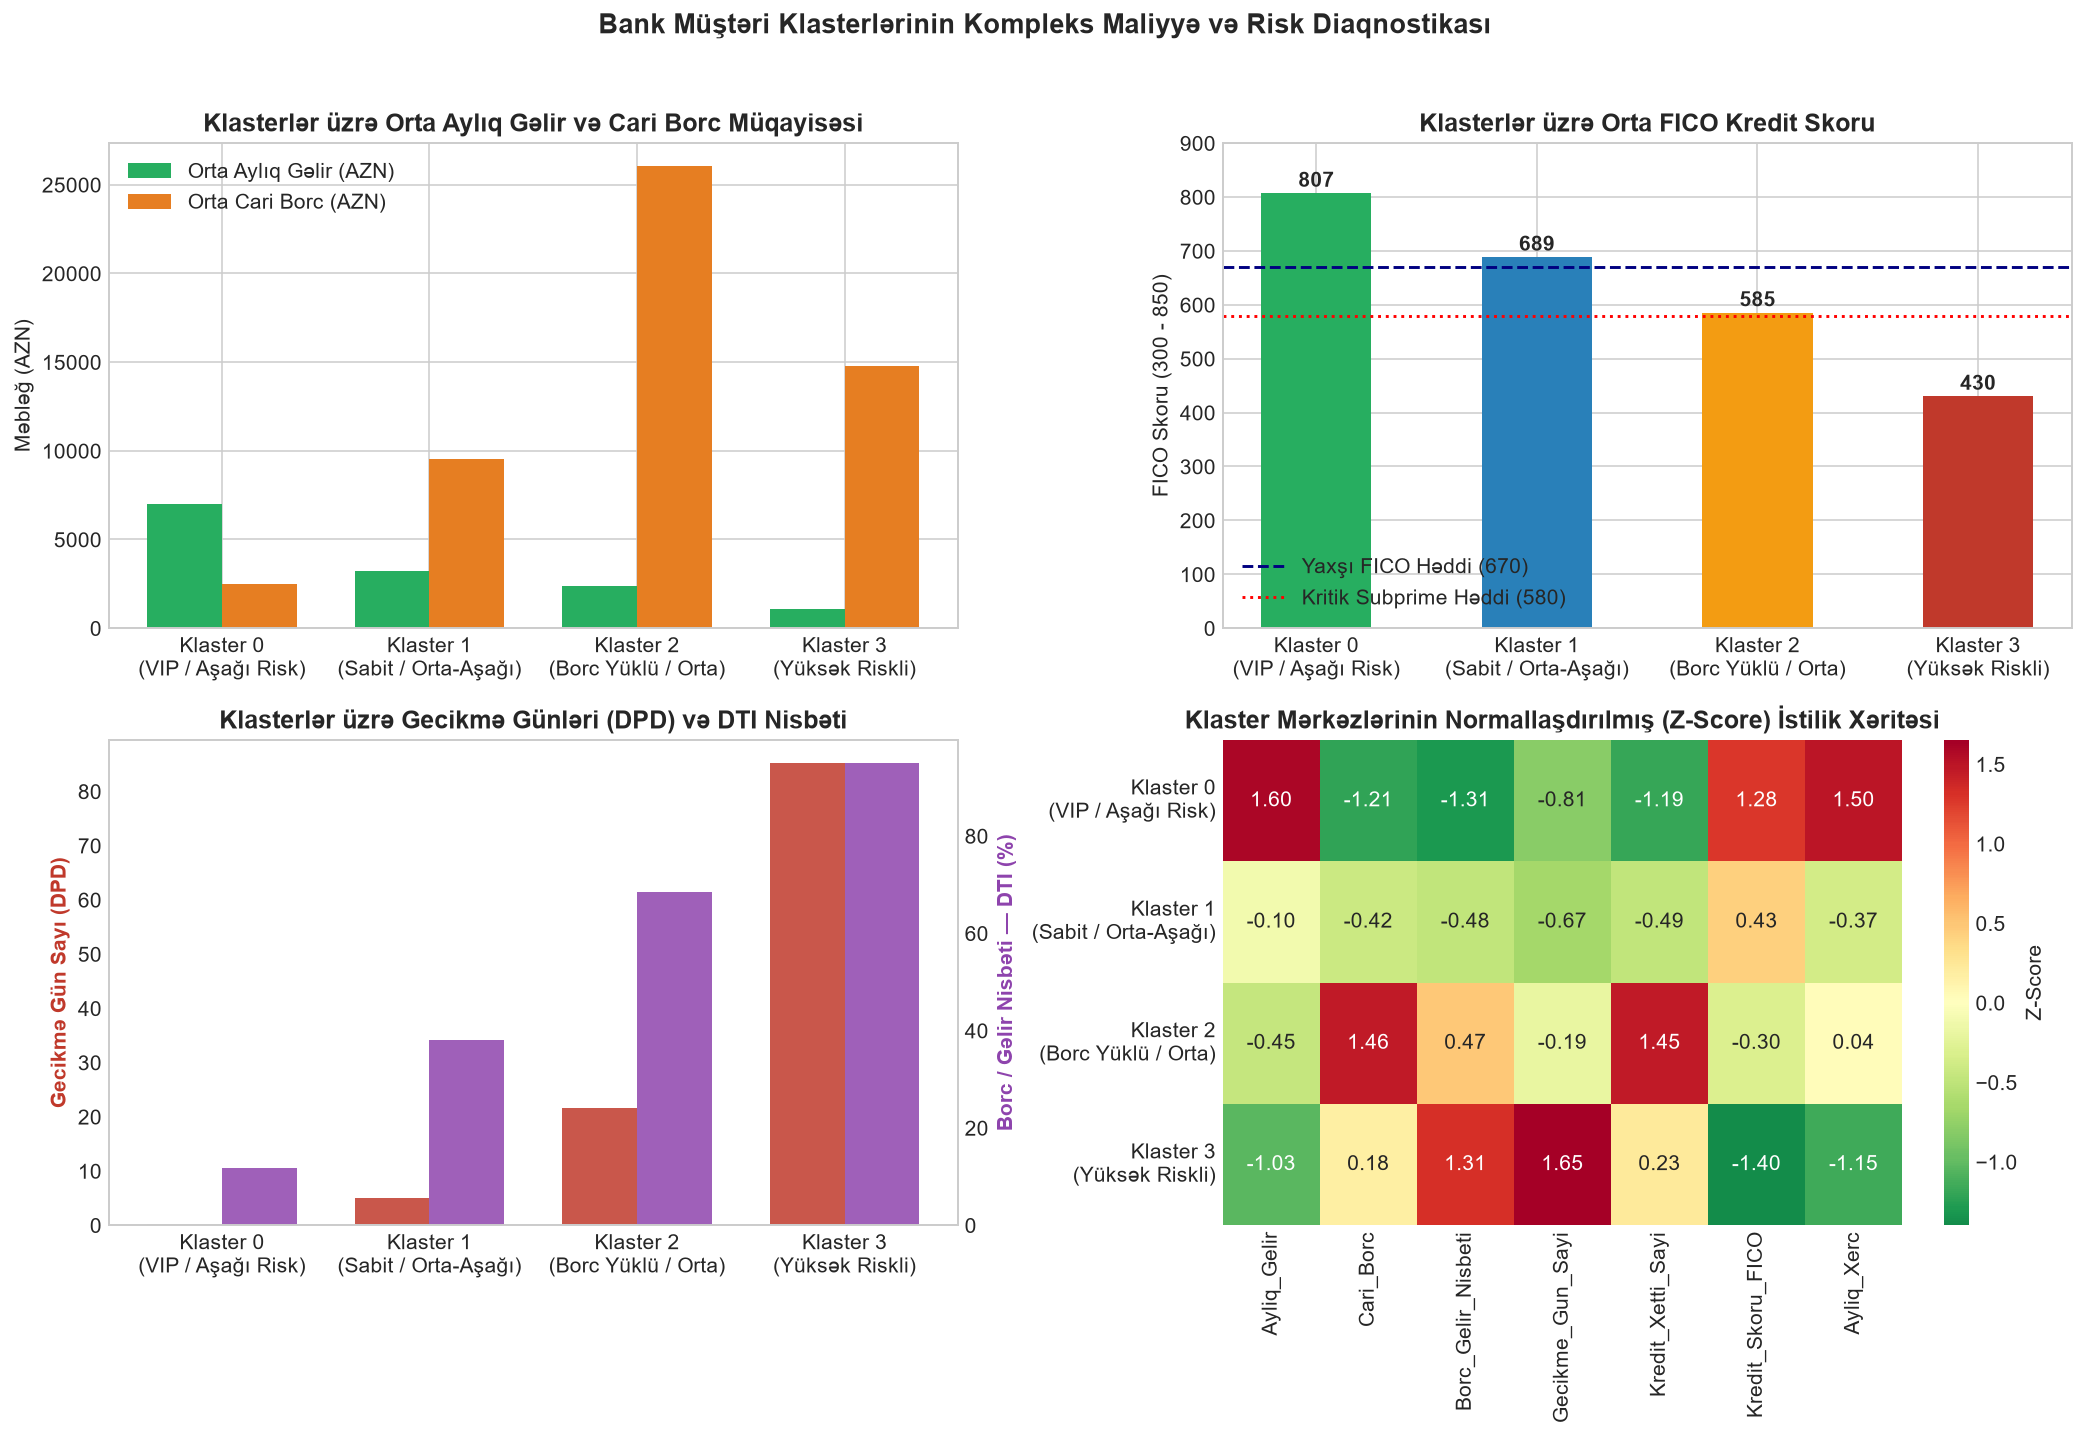

In [14]:
# Klaster Profillərinin Əyani Biznes Vizuallaşdırılması (Standartlaşdırılmış İstilik Xəritəsi + Əsas Göstəricilər)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

short_labels = ["Klaster 0\n(VIP / Aşağı Risk)", "Klaster 1\n(Sabit / Orta-Aşağı)", "Klaster 2\n(Borc Yüklü / Orta)", "Klaster 3\n(Yüksək Riskli)"]

# 1. Orta Aylıq Gəlir vs Cari Borc
x_pos = np.arange(optimal_k)
width = 0.36
axes[0, 0].bar(x_pos - width/2, cluster_profile["Ayliq_Gelir"], width, label="Orta Aylıq Gəlir (AZN)", color="#27ae60")
axes[0, 0].bar(x_pos + width/2, cluster_profile["Cari_Borc"], width, label="Orta Cari Borc (AZN)", color="#e67e22")
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(short_labels)
axes[0, 0].set_title("Klasterlər üzrə Orta Aylıq Gəlir və Cari Borc Müqayisəsi")
axes[0, 0].set_ylabel("Məbləğ (AZN)")
axes[0, 0].legend()

# 2. Orta FICO Kredit Skoru
bars_fico = axes[0, 1].bar(short_labels, cluster_profile["Kredit_Skoru_FICO"], color=palette_colors, width=0.5)
axes[0, 1].axhline(y=670, color="navy", linestyle="--", linewidth=1.5, label="Yaxşı FICO Həddi (670)")
axes[0, 1].axhline(y=580, color="red", linestyle=":", linewidth=1.5, label="Kritik Subprime Həddi (580)")
for bar in bars_fico:
    yval = bar.get_height()
    axes[0, 1].annotate(f"{yval:.0f}", (bar.get_x() + bar.get_width()/2, yval + 12), ha="center", fontweight="bold")
axes[0, 1].set_ylim(0, 900)
axes[0, 1].set_title("Klasterlər üzrə Orta FICO Kredit Skoru")
axes[0, 1].set_ylabel("FICO Skoru (300 - 850)")
axes[0, 1].legend(loc="lower left")

# 3. Orta Gecikmə Gün Sayı (DPD) və DTI
ax3_twin = axes[1, 0].twinx()
b1 = axes[1, 0].bar(x_pos - width/2, cluster_profile["Gecikme_Gun_Sayi"], width, color="#c0392b", alpha=0.85, label="Orta Gecikmə Günü (Sol ox)")
b2 = ax3_twin.bar(x_pos + width/2, cluster_profile["Borc_Gelir_Nisbeti"] * 100, width, color="#8e44ad", alpha=0.85, label="Orta DTI % (Sağ ox)")
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(short_labels)
axes[1, 0].set_ylabel("Gecikmə Gün Sayı (DPD)", color="#c0392b", fontweight="bold")
ax3_twin.set_ylabel("Borc / Gəlir Nisbəti — DTI (%)", color="#8e44ad", fontweight="bold")
axes[1, 0].set_title("Klasterlər üzrə Gecikmə Günləri (DPD) və DTI Nisbəti")
axes[1, 0].grid(False)
ax3_twin.grid(False)

# 4. Z-Score İstilik Xəritəsi (Klaster Mərkəzlərinin Profil Matrisi)
z_profile = pd.DataFrame(centroids_scaled, index=short_labels, columns=feature_cols)
sns.heatmap(z_profile, annot=True, fmt=".2f", cmap="RdYlGn_r", center=0, cbar_kws={"label": "Z-Score"}, ax=axes[1, 1])
axes[1, 1].set_title("Klaster Mərkəzlərinin Normallaşdırılmış (Z-Score) İstilik Xəritəsi")

plt.suptitle("Bank Müştəri Klasterlərinin Kompleks Maliyyə və Risk Diaqnostikası", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 5.2. Bank Rəhbərliyi Üçün Kredit Siyasəti və Strateji Tövsiyələr

Aşağıda hər bir müştəri klasterinin ətraflı maliyyə diaqnostikası və **Bankın Kredit Komitəsi / Risk İdarəetmə Departamenti** üçün konkret fəaliyyət planı təqdim olunur:

---

#### 🟢 Klaster 0: Aşağı Riskli / Etibarlı Müştərilər (*VIP / Prime Segment*)
- **Maliyyə Portreti:**
  - **Orta Aylıq Gəlir:** ~7,024 AZN (Portfelin ən yüksək gəlirli təbəqəsi)
  - **Cari Borc və DTI:** ~2,500 AZN cari borc, **~12% DTI** (Çox sağlam, gəlirin böyük hissəsi sərbəstdir)
  - **Gecikmə Gün Sayı:** ~0.2 gün (Tam ödəniş intizamı)
  - **Orta FICO Skoru:** ~807 bal (*Exceptional*)
- **Kredit Siyasəti Tövsiyəsi:**
  - **Faiz Dərəcəsi:** Rəqabətli imtiyazlı faiz dərəcəsi (standart tarifdən **2.5% – 3.5% aşağı**).
  - **Kredit Limiti:** Yüksək/Avtomatik təsdiqlənən (*Pre-approved*) kredit xətləri (aylıq gəlirin 15–20 mislinədək).
  - **Girov və Zamin Tələbi:** Nağd və istehlak kreditlərində **girovsuz və zaminsiz** sürətli rəsmiləşdirmə.
  - **Biznes Strategiyası:** *Private Banking*, Premium kredit kartları (*Cashback / Miles*), ipoteka və investisiya məhsullarının aktiv çarpaz satışı (*cross-sell*).

---

#### 🔵 Klaster 1: Orta-Aşağı Riskli / Sabit Müştərilər (*Standard / Core Retail*)
- **Maliyyə Portreti:**
  - **Orta Aylıq Gəlir:** ~3,200 AZN (Sabit orta-yüksək gəlir)
  - **Cari Borc və DTI:** ~9,535 AZN cari borc, **~38% DTI** (Optimal norm daxilində)
  - **Gecikmə Gün Sayı:** ~5 gün (Yalnız qısamüddətli texniki gecikmələr)
  - **Orta FICO Skoru:** ~689 bal (*Good*)
- **Kredit Siyasəti Tövsiyəsi:**
  - **Faiz Dərəcəsi:** Bankın baza/standart pərakəndə kredit faiz dərəcəsi.
  - **Kredit Limiti:** DTI əmsalı **45%-i keçməmək şərti ilə** orta-yüksək kredit limiti (aylıq gəlirin 8–10 mislinədək).
  - **Girov və Zamin Tələbi:** Kiçik və orta məbləğli kreditlərdə rəsmi əməkhaqqı arayışı kifayətdir; yalnız iri məbləğli (məs. >30,000 AZN) kreditlərdə zamin və ya avto/əmlak girovu tələb olunmalıdır.
  - **Biznes Strategiyası:** Sabit gəlir gətirən əsas pərakəndə kütlədir (*25%*). Sadiqlik proqramları və taksit kartları ilə müştəri bağlılığını artırmaq tövsiyə olunur.

---

#### 🟠 Klaster 2: Orta Riskli / Potensial Borc Yüklü Müştərilər (*Watchlist / Leveraged*)
- **Maliyyə Portreti:**
  - **Orta Aylıq Gəlir:** ~2,403 AZN
  - **Cari Borc və Kredit Xətləri:** ~26,043 AZN cari borc və orta hesabla **~9 aktiv kredit xətti** (Çoxsaylı paralel öhdəliklər)
  - **Borc / Gəlir Nisbəti (DTI):** ~68% (Yüksək borc yükü — gəlir azalmasına həssas)
  - **Gecikmə Gün Sayı:** ~22 gün (Tez-tez 15–30 günlük gecikmələrə düşürlər)
  - **Orta FICO Skoru:** ~585 bal (*Fair / Near-Prime*)
- **Kredit Siyasəti Tövsiyəsi:**
  - **Faiz Dərəcəsi:** Risk mükafatı (*Risk Premium*) əlavə edilmiş faiz dərəcəsi (standartdan **+3% – +5% yuxarı**).
  - **Kredit Limiti:** Yeni nağd kredit limitlərinin dondurulması və ya ciddi məhdudlaşdırılması; əvəzində **Borcların Birləşdirilməsi (*Debt Consolidation / Refinancing*)** məhsulunun təklif edilməsi (aylıq ödəniş yükünü azaltmaq üçün müddətin uzadılması).
  - **Girov və Zamin Tələbi:** Hər hansı yeni kredit və ya yenidən maliyyələşdirmə yalnız **rəsmi zamin və ya likvid girov** təminatı ilə verilməlidir.
  - **Erkən Xəbərdarlıq (*Early Warning*):** Ödəniş tarixindən 3 gün əvvəl avtomatik SMS/Push bildirişlərinin göndərilməsi.

---

#### 🔴 Klaster 3: Yüksək Riskli / Gecikməyə Meyilli Müştərilər (*High Risk / Subprime*)
- **Maliyyə Portreti:**
  - **Orta Aylıq Gəlir:** ~1,095 AZN (Aşağı gəlir)
  - **Cari Borc və DTI:** ~14,754 AZN borc, **~95% DTI** (Kredit ödəmə qabiliyyəti kritik həddədir)
  - **Gecikmə Gün Sayı:** ~85 gün (Qeyri-işlək kredit — *NPL / Non-Performing Loan* zonasına keçid)
  - **Orta FICO Skoru:** ~430 bal (*Poor / Subprime*)
- **Kredit Siyasəti Tövsiyəsi:**
  - **Faiz Dərəcəsi və Yeni Kredit:** Yeni təminatsız kreditlərin verilməsinə **tam qadağa (*Hard Stop / Reject*)**.
  - **Kredit Limiti:** Mövcud kredit kartı və overdraft limitlərinin dərhal bloklanması və ya sıfırlanması.
  - **Girov və Restrukturizasiya:** Mövcud problemli borcların geri qaytarılması üçün **kreditin restrukturizasiyası** (cərimə faizlərinin güzəşti müqabilində əsas borcun girov/zaminlə təmin edilərək yeni qrafikə salınması) və *Soft/Hard Collection* (Problemli Kreditlər Departamenti) tərəfindən fərdi nəzarətə götürülməsi.

---
### 📊 Yekun Xülasə Cədvəli (İdarə Heyəti Üçün Qərar Matrisi)

| Klaster | Bank Statusu | Müştəri Payı | Yeni Kredit Qərarı | Faiz Siyasəti | Girov / Təminat | Əsas Fokus |
| :---: | :--- | :---: | :--- | :--- | :--- | :--- |
| **Klaster 0** | **Aşağı Riskli (VIP)** | 25% | ✅ Avtomatik Təsdiq | Endirimli (-3%) | Tələb olunmur | Limit artımı & Çarpaz satış |
| **Klaster 1** | **Sabit (Standart)** | 25% | ✅ Standart Təsdiq | Baza dərəcəsi | İri məbləğdə zamin | Portfelin saxlanması |
| **Klaster 2** | **Orta Riskli (Borc Yüklü)** | 25% | ⚠️ Məhdud / Konsolidasiya | Risk əlavəli (+4%) | Zamin / Girov şərtdir | Borcların birləşdirilməsi |
| **Klaster 3** | **Yüksək Riskli (Gecikməli)** | 25% | ❌ İmtina (Stop-Kredit) | — | 100%+ Likvid Girov | Restrukturizasiya & Yığım |